Metrics being used 

- **Anomaly:** Target = observed 3-month rainfall total − climatological mean (cell, window-start month).
- **Standardised anomaly:** `z = target_anom_mm / target_sd`, with SD floored at 5 mm.
- **Forecast:** `pred_z = 0`, so predicted rainfall = climatological mean.
- **MSE:** Mean squared error between observed and predicted standardized anomalies.
- **MSE skill score:** `1 − MSE(model) / MSE(climatology)`. Climatology's MSE is `mean(z²)`.
- **Skill:** 0 by definition. Every later model must beat this baseline.
- **R²:** `1 − SSE / SST`. It compares predictions against the mean of the evaluated observations. Unlike MSE skill, it does not use climatology as its reference.
- **ACC (Anomaly Correlation Coefficient):** Pearson correlation between predicted and observed anomalies. It measures whether the model captures the direction and pattern of rainfall anomalies (wetter or drier than normal), regardless of error magnitude.
- **RMSE:** Root mean squared error. Measures the typical prediction error, penalising large errors more heavily. Report in standardized units and mm.
- **MAE:** Mean absolute error. Measures the average absolute prediction error, with less sensitivity to extreme errors than RMSE.
- **Bias:** Mean(predicted − observed). Positive means the model predicts wetter conditions than observed; negative means drier conditions.
- **Tercile accuracy:** Percentage of predictions correctly classified as below-normal, near-normal or above-normal rainfall.
- **HSS (Heidke Skill Score):** Measures categorical forecasting skill compared with chance agreement. 1 is perfect, 0 is chance-level, and negative means worse than chance.
- **Evaluation:** Report metrics on validation data, both with all observations and after excluding rows where `|observed z| > 6`.

In [1]:
#Imports, environment and MLflow configuration
import os
import json
import hashlib
import subprocess
import tempfile
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mlflow
from dotenv import load_dotenv

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

load_dotenv("../../.env")

os.environ["MLFLOW_TRACKING_USERNAME"] = "Sharanya-0224"
os.environ["MLFLOW_TRACKING_PASSWORD"] = os.environ["DAGSHUB_USER_TOKEN"]

mlflow.set_tracking_uri(
    "https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow"
)

mlflow.set_system_metrics_sampling_interval(1)

print("MLflow tracking configured:", mlflow.get_tracking_uri())
print("MLflow version:", mlflow.__version__)

/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow tracking configured: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow
MLflow version: 3.17.1


In [2]:
#Experiment names and project configuration
EXPERIMENTS = {
    "baselines": "rain_v2_3month_baselines",
    "ridge": "rain_v2_3month_ridge",
    "lightgbm": "rain_v2_3month_lightgbm"
}

DATA_PATH = "../data/processed/rain_v2_3month_dataset_02.parquet"
FEATURE_PATH = "../data/processed/rain_v2_3month_feature_list_02.json"

TRAIN_END = 2002
VAL_START = 2003
VAL_END = 2013
TEST_START = 2014
TEST_END = 2025

OUTLIER_THRESHOLD = 6
SD_FLOOR = 5
RANDOM_STATE = 42

GIT_COMMIT = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"],
    text=True
).strip()

print("Git commit:", GIT_COMMIT)
print("Experiments:", EXPERIMENTS)

Git commit: c79e53c
Experiments: {'baselines': 'rain_v2_3month_baselines', 'ridge': 'rain_v2_3month_ridge', 'lightgbm': 'rain_v2_3month_lightgbm'}


In [3]:
#load dataset and feature list
df = pd.read_parquet(DATA_PATH)

with open(FEATURE_PATH) as f:
    features = json.load(f)["inputs"]

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFeature count:", len(features))
print("\nFeatures:")
print(features)

print("\nSample:")
display(df.head())

print("\nSplit counts:")
print(df["split"].value_counts())

Dataset shape: (7306839, 34)

Columns:
['key', 'state', 'region', 'year', 'month', 'split', 'target_mm', 'target_mean', 'target_sd', 'target_anom_mm', 'target_z', 'lat', 'lon', 'month_sin', 'month_cos', 'region_central', 'region_east_northeast', 'region_northwest', 'region_south_peninsula', 'rain_z_t', 'rain_z_lag1', 'rain_z_roll3', 'rain_z_roll6', 'nino34_t', 'nino34_lag1', 'nino34_lag2', 'nino34_lag3', 'nino34_mean3', 'nino34_chg3', 'dmi_t', 'dmi_lag1', 'dmi_lag2', 'dmi_lag3', 'dmi_mean3']

Feature count: 23

Features:
['lat', 'lon', 'month_sin', 'month_cos', 'region_central', 'region_east_northeast', 'region_northwest', 'region_south_peninsula', 'rain_z_t', 'rain_z_lag1', 'rain_z_roll3', 'rain_z_roll6', 'nino34_t', 'nino34_lag1', 'nino34_lag2', 'nino34_lag3', 'nino34_mean3', 'nino34_chg3', 'dmi_t', 'dmi_lag1', 'dmi_lag2', 'dmi_lag3', 'dmi_mean3']

Sample:


,key,state,region,year,month,split,target_mm,target_mean,target_sd,target_anom_mm,...,nino34_lag1,nino34_lag2,nino34_lag3,nino34_mean3,nino34_chg3,dmi_t,dmi_lag1,dmi_lag2,dmi_lag3,dmi_mean3
0,8257700,Kerala,south_peninsula,1901,6,train,107.908134,324.367981,150.969482,-216.459854,...,-0.19,-0.13,0.05,-0.193333,-0.31,-0.618,-0.553,-0.513,-0.720,-0.561333
1,8257700,Kerala,south_peninsula,1901,7,train,199.309631,440.521515,141.970795,-241.211868,...,-0.26,-0.19,-0.13,-0.250000,-0.17,-0.712,-0.618,-0.553,-0.513,-0.627667
2,8257700,Kerala,south_peninsula,1901,8,train,633.377930,563.170105,178.762619,70.207809,...,-0.30,-0.26,-0.19,-0.313333,-0.19,-0.825,-0.712,-0.618,-0.553,-0.718333
3,8257700,Kerala,south_peninsula,1901,9,train,641.470947,513.533081,191.701355,127.937836,...,-0.38,-0.30,-0.26,-0.326667,-0.04,-1.029,-0.825,-0.712,-0.618,-0.855333
4,8257700,Kerala,south_peninsula,1901,10,train,518.178101,287.216797,142.348267,230.961288,...,-0.30,-0.38,-0.30,-0.330000,-0.01,-0.774,-1.029,-0.825,-0.712,-0.876000



Split counts:
split
train    5980344
test      693996
val       632499
Name: count, dtype: int64


In [4]:
def metrics(y_true, y_pred, y_true_mm, y_pred_mm):
    mse = np.mean((y_true - y_pred) ** 2)
    mse_clim = np.mean(y_true ** 2)

    return {
        "mse": mse,
        "mse_skill": 1 - mse / mse_clim if mse_clim > 0 else np.nan,
        "rmse_z": np.sqrt(mse),
        "mae_z": np.mean(np.abs(y_true - y_pred)),
        "bias_z": np.mean(y_pred - y_true),
        "acc": np.corrcoef(y_true, y_pred)[0, 1]
            if np.std(y_true) > 0 and np.std(y_pred) > 0 else np.nan,
        "r2": 1 - np.sum((y_true - y_pred) ** 2) /
            np.sum((y_true - np.mean(y_true)) ** 2)
            if np.sum((y_true - np.mean(y_true)) ** 2) > 0 else np.nan,
        "rmse_mm": np.sqrt(np.mean((y_true_mm - y_pred_mm) ** 2)),
        "mae_mm": np.mean(np.abs(y_true_mm - y_pred_mm)),
        "bias_mm": np.mean(y_pred_mm - y_true_mm)
    }

In [5]:
train_df = df.loc[df["split"] == "train"]

tercile_thresholds = (
    train_df.groupby(["key", "month"])["target_z"]
    .quantile([1/3, 2/3])
    .unstack()
    .reset_index()
)

tercile_thresholds.columns = [
    "key", "month", "lower_threshold", "upper_threshold"
]

print("Threshold groups:", len(tercile_thresholds))
display(tercile_thresholds.head())

Threshold groups: 59124


,key,month,lower_threshold,upper_threshold
0,8257700,1,-0.538816,0.387733
1,8257700,2,-0.516290,0.216879
2,8257700,3,-0.575255,0.391723
3,8257700,4,-0.523810,0.221569
4,8257700,5,-0.457436,0.154830


In [6]:
def categorical_metrics(y_true, y_pred, lower, upper):
    def classify(values):
        return np.where(
            values < lower, 0,
            np.where(values > upper, 2, 1)
        )

    observed = classify(y_true)
    predicted = classify(y_pred)

    confusion = pd.crosstab(
        pd.Series(observed),
        pd.Series(predicted)
    ).reindex(index=[0, 1, 2], columns=[0, 1, 2], fill_value=0).values

    n = confusion.sum()
    accuracy = np.trace(confusion) / n

    expected = np.sum(
        confusion.sum(axis=0) * confusion.sum(axis=1)
    ) / n**2

    hss = (
        (accuracy - expected) / (1 - expected)
        if expected < 1 else np.nan
    )

    return {
        "tercile_accuracy": accuracy,
        "hss": hss
    }

In [7]:
#reusable evaluation function - only on train and validation
def evaluate_model(part, pred_z):
    assert part["split"].nunique() == 1
    assert "test" not in part["split"].values
    assert len(part) == len(pred_z)

    result = part[
        ["key", "month", "target_z", "target_anom_mm", "target_sd"]
    ].copy()

    result["pred_z"] = np.asarray(pred_z)

    result = result.merge(
        tercile_thresholds,
        on=["key", "month"],
        how="left",
        validate="many_to_one"
    )

    result["pred_anom_mm"] = result["pred_z"] * result["target_sd"]

    def calculate(data):
        continuous = metrics(
            data["target_z"].values,
            data["pred_z"].values,
            data["target_anom_mm"].values,
            data["pred_anom_mm"].values
        )

        categorical = categorical_metrics(
            data["target_z"].values,
            data["pred_z"].values,
            data["lower_threshold"].values,
            data["upper_threshold"].values
        )

        return {**continuous, **categorical, "n": len(data)}

    all_metrics = calculate(result)

    filtered = result[result["target_z"].abs() <= OUTLIER_THRESHOLD]
    filtered_metrics = calculate(filtered)

    return {
        "all": all_metrics,
        "no_extremes": filtered_metrics
    }

In [8]:
#regional and seasonal evaluations
def get_season(month):
    return {
        12: "DJF", 1: "DJF", 2: "DJF",
        3: "MAM", 4: "MAM", 5: "MAM",
        6: "JJA", 7: "JJA", 8: "JJA",
        9: "SON", 10: "SON", 11: "SON"
    }[month]


def evaluate_by_group(part, pred_z):
    results = {}

    groups = {
        "region": part["region"],
        "season": part["month"].map(get_season)
    }

    for group_type, group_values in groups.items():
        for group_name in sorted(group_values.unique()):
            mask = (group_values == group_name).values

            results[f"{group_type}_{group_name}"] = evaluate_model(
                part.iloc[np.where(mask)[0]],
                np.asarray(pred_z)[mask]
            )

    return results

In [9]:
#resampling of years in order to set confidence intervals for metrics like ACC and MSE Skill
def bootstrap_ci(part, pred_z, n_boot=200, seed=RANDOM_STATE):
    assert "test" not in part["split"].values

    rng = np.random.default_rng(seed)
    years = part["year"].unique()

    data = part[
        ["key", "month", "year", "target_z", "target_anom_mm", "target_sd"]
    ].copy()

    data["pred_z"] = np.asarray(pred_z)

    data = data.merge(
        tercile_thresholds,
        on=["key", "month"],
        how="left",
        validate="many_to_one"
    )

    def calculate(sample):
        return {
            **metrics(
                sample["target_z"].values,
                sample["pred_z"].values,
                sample["target_anom_mm"].values,
                (sample["pred_z"] * sample["target_sd"]).values
            ),
            **categorical_metrics(
                sample["target_z"].values,
                sample["pred_z"].values,
                sample["lower_threshold"].values,
                sample["upper_threshold"].values
            )
        }

    scores = []

    for _ in range(n_boot):
        sampled_years = rng.choice(years, size=len(years), replace=True)

        indices = np.concatenate([
            np.flatnonzero(data["year"].values == year)
            for year in sampled_years
        ])

        sample = data.iloc[indices]
        scores.append(calculate(sample))

    scores = pd.DataFrame(scores)

    return pd.DataFrame({
        "lower_95": scores.quantile(0.025),
        "upper_95": scores.quantile(0.975)
    })

In [10]:
#different dataframes created for training and validation
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Training years:", train_df["year"].min(), "-", train_df["year"].max())
print("Validation years:", val_df["year"].min(), "-", val_df["year"].max())

Training rows: 5980344
Validation rows: 632499
Training years: 1901 - 2002
Validation years: 2003 - 2013


Baseline 1: Climatology

It is a simple baseline model that assumes future rainfall will be equal to the historical average rainfall for that location and time of year. It does not use other climate factors or learn patterns from recent rainfall.

Anamoly = Observed Rainfall - Historical Avg Rainfall 

z = Anamoly/ historical SD

for climatology z = 0 (assumption)  => historical average rainfall is predicted by the model.

In [13]:
train_pred_clim = np.zeros(len(train_df))
val_pred_clim = np.zeros(len(val_df))

print("Climatology predictions created.")
print("Training predictions:", len(train_pred_clim))
print("Validation predictions:", len(val_pred_clim))
print("Unique prediction value:", np.unique(val_pred_clim))

Climatology predictions created.
Training predictions: 5980344
Validation predictions: 632499
Unique prediction value: [0.]


2026/11/12 01:47:23 INFO mlflow.tracking.fluent: Experiment with name 'rain_v2_3month_climatology' does not exist. Creating a new experiment.
2026/11/12 01:47:37 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/12 01:47:37 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run climatology_train at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/7/runs/0a9560e65cad4bd2b0c27dfa235ea370
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/7


2026/11/12 01:54:58 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/12 01:55:01 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


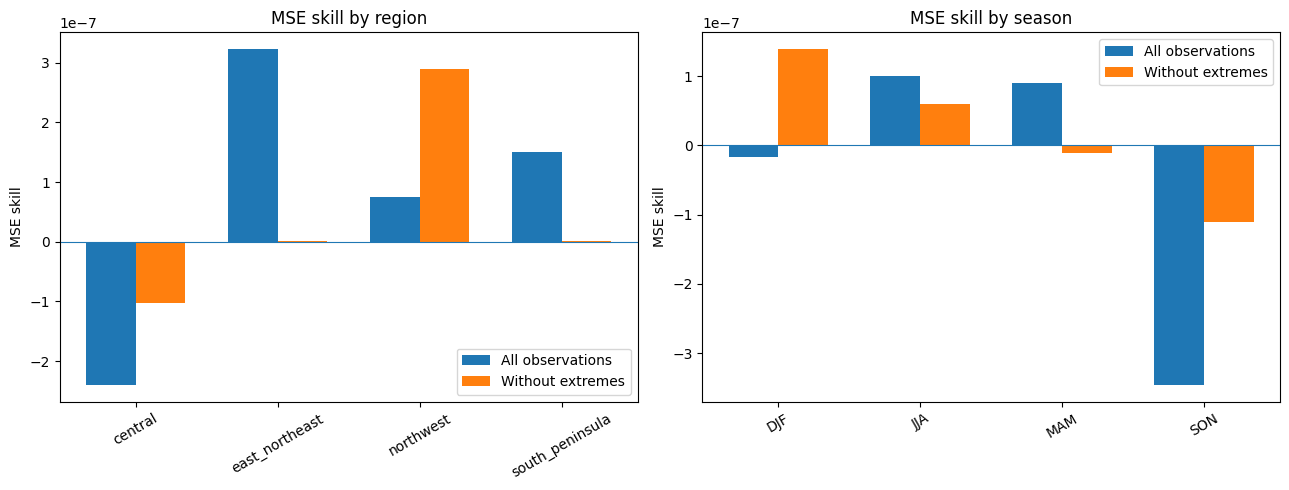

Climatology training run logged successfully.


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,0.990924,5.271052e-07,0.995452,0.748158,-0.000904,NaN,-0.000002,166.151396,93.177026,-0.200764,0.330445,-0.017652,5980344.0
no_extremes,0.957985,-1.679408e-07,0.978767,0.743968,0.003782,NaN,-0.000015,164.455592,92.850366,0.187612,0.330305,-0.018043,5976377.0


In [14]:
#Climatology on Train split

clim_train_metrics = evaluate_model(train_df, train_pred_clim)
clim_train_groups = evaluate_by_group(train_df, train_pred_clim)

# calculate dataset checksum
md5 = hashlib.md5()

with open(DATA_PATH, "rb") as file:
    for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
        md5.update(chunk)

DATASET_MD5 = md5.hexdigest()

# create training performance graph
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, group_type in zip(axes, ["region", "season"]):
    names = [
        name for name in clim_train_groups
        if name.startswith(group_type + "_")
    ]

    labels = [name.replace(group_type + "_", "") for name in names]
    all_scores = [
        clim_train_groups[name]["all"]["mse_skill"] for name in names
    ]
    filtered_scores = [
        clim_train_groups[name]["no_extremes"]["mse_skill"] for name in names
    ]

    x = np.arange(len(names))
    width = 0.35

    ax.bar(x - width / 2, all_scores, width, label="All observations")
    ax.bar(x + width / 2, filtered_scores, width, label="Without extremes")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30)
    ax.set_title(f"MSE skill by {group_type}")
    ax.set_ylabel("MSE skill")
    ax.axhline(0, linewidth=0.8)
    ax.legend()

plt.tight_layout()

# log the training run
mlflow.set_experiment("rain_v2_3month_climatology")

with mlflow.start_run(
    run_name="climatology_train",
    log_system_metrics=True
):
    mlflow.log_params({
        "model": "climatology",
        "forecast_horizon_months": 3,
        "target": "target_z",
        "training_period": "1901-2002",
        "normal_years": "1901-2002",
        "sd_floor_mm": SD_FLOOR,
        "outlier_threshold": OUTLIER_THRESHOLD
    })

    mlflow.set_tags({
        "model_type": "baseline",
        "baseline_method": "historical_climatology",
        "evaluation_split": "train",
        "git_commit": GIT_COMMIT,
        "dataset_md5": DATASET_MD5
    })

    # log overall metrics
    for subset, scores in clim_train_metrics.items():
        for metric_name, value in scores.items():
            if np.isfinite(value):
                mlflow.log_metric(
                    f"train/{subset}/{metric_name}", float(value)
                )

    # log regional and seasonal metrics
    for group_name, results in clim_train_groups.items():
        for subset, scores in results.items():
            for metric_name, value in scores.items():
                if np.isfinite(value):
                    mlflow.log_metric(
                        f"train/{group_name}/{subset}/{metric_name}",
                        float(value)
                    )

    # log graph
    with tempfile.TemporaryDirectory() as temp_dir:
        graph_path = os.path.join(temp_dir, "climatology_train.png")
        fig.savefig(graph_path, dpi=150, bbox_inches="tight")
        mlflow.log_artifact(graph_path, artifact_path="graphs")

plt.show()
plt.close(fig)

print("Climatology training run logged successfully.")
display(pd.DataFrame(clim_train_metrics).T)

Climatology predicts zero rainfall anomaly, equivalent to the historical average 3-month rainfall. Its MSE skill is approximately zero because it serves as the reference model. It has almost no overall bias, but its tercile accuracy is around 33%, indicating chance-level categorical prediction. These results establish the baseline performance against which more advanced models will be compared.

2026/11/12 02:05:32 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/12 02:05:32 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run climatology_validation at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/7/runs/742337b2546a4c38b28dc0de04a774db
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/7


2026/11/12 02:14:32 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/12 02:14:34 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


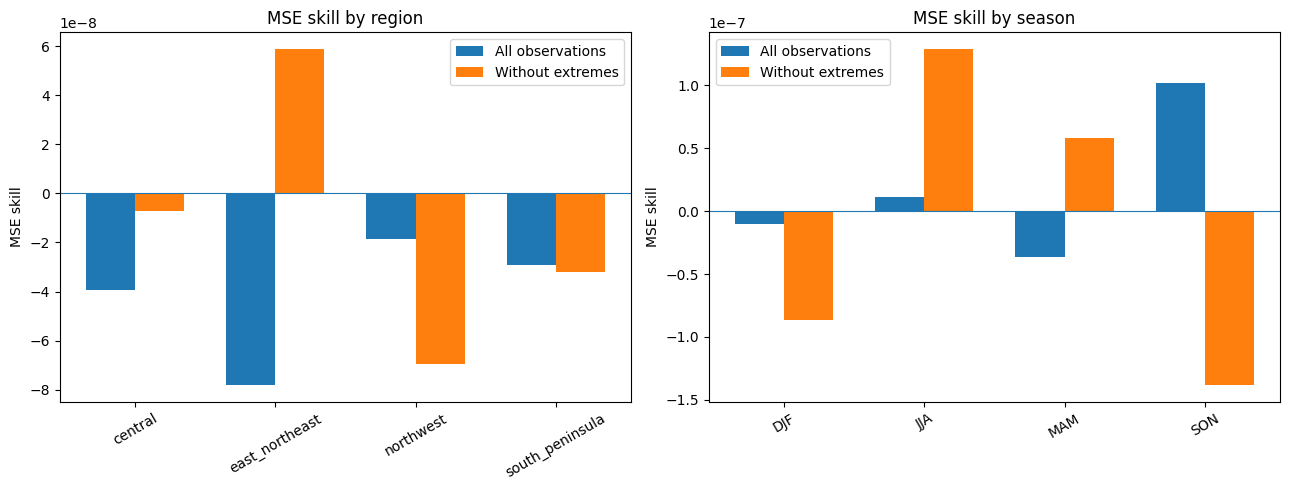

Climatology validation run logged successfully.

Overall validation metrics:


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,1.464680,1.434418e-07,1.210240,0.840576,-0.021711,NaN,-0.000322,192.929803,105.844485,-2.066688,0.309833,-0.010074,632499.0
no_extremes,1.168192,5.493135e-08,1.080829,0.814692,0.006793,NaN,-0.000040,184.549540,103.887002,0.222795,0.309990,-0.010538,630482.0



Bootstrap confidence intervals:
all


,lower_95,upper_95
mse,1.277150e+00,1.628219e+00
mse_skill,-2.642190e-07,2.487617e-07
rmse_z,1.130111e+00,1.276017e+00
mae_z,8.054587e-01,8.722234e-01
bias_z,-9.423627e-02,4.787071e-02
acc,NaN,NaN
r2,-5.626597e-03,-3.957884e-06
rmse_mm,1.830962e+02,2.000720e+02
mae_mm,1.014581e+02,1.108849e+02
bias_mm,-1.237787e+01,9.734900e+00


no_extremes


,lower_95,upper_95
mse,1.067496e+00,1.273786e+00
mse_skill,-2.861321e-07,2.550769e-07
rmse_z,1.033197e+00,1.128621e+00
mae_z,7.853550e-01,8.443045e-01
bias_z,-6.077604e-02,7.179096e-02
acc,NaN,NaN
r2,-5.329392e-03,-1.946917e-06
rmse_mm,1.753805e+02,1.906092e+02
mae_mm,9.927238e+01,1.089549e+02
bias_mm,-1.022477e+01,1.215547e+01


In [15]:
#climatology on validation split
clim_val_metrics = evaluate_model(val_df, val_pred_clim)
clim_val_groups = evaluate_by_group(val_df, val_pred_clim)

# prepare validation data for year-block bootstrap
boot_data = val_df[
    ["key", "month", "year", "target_z", "target_anom_mm", "target_sd"]
].copy()

boot_data["pred_z"] = val_pred_clim

boot_data = boot_data.merge(
    tercile_thresholds,
    on=["key", "month"],
    how="left",
    validate="many_to_one"
)

z_true = boot_data["target_z"].to_numpy()
z_pred = boot_data["pred_z"].to_numpy()
anom_mm = boot_data["target_anom_mm"].to_numpy()
sd = boot_data["target_sd"].to_numpy()
lower = boot_data["lower_threshold"].to_numpy()
upper = boot_data["upper_threshold"].to_numpy()
years = boot_data["year"].to_numpy()

year_indices = {
    year: np.flatnonzero(years == year)
    for year in np.unique(years)
}

rng = np.random.default_rng(RANDOM_STATE)
bootstrap_scores = {"all": [], "no_extremes": []}

for _ in range(200):
    sampled_years = rng.choice(
        list(year_indices), size=len(year_indices), replace=True
    )
    indices = np.concatenate([year_indices[y] for y in sampled_years])

    for name, selected in [
        ("all", indices),
        ("no_extremes", indices[np.abs(z_true[indices]) <= OUTLIER_THRESHOLD])
    ]:
        if len(selected) == 0:
            continue

        scores = metrics(
            z_true[selected],
            z_pred[selected],
            anom_mm[selected],
            z_pred[selected] * sd[selected]
        )

        scores.update(categorical_metrics(
            z_true[selected],
            z_pred[selected],
            lower[selected],
            upper[selected]
        ))

        bootstrap_scores[name].append(scores)

# calculate confidence intervals
clim_bootstrap_ci = {}

for name, scores in bootstrap_scores.items():
    scores_df = pd.DataFrame(scores)
    clim_bootstrap_ci[name] = pd.DataFrame({
        "lower_95": scores_df.quantile(0.025),
        "upper_95": scores_df.quantile(0.975)
    })

# create validation performance graph
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, group_type in zip(axes, ["region", "season"]):
    names = [
        name for name in clim_val_groups
        if name.startswith(group_type + "_")
    ]

    labels = [name.replace(group_type + "_", "") for name in names]
    all_scores = [
        clim_val_groups[name]["all"]["mse_skill"] for name in names
    ]
    filtered_scores = [
        clim_val_groups[name]["no_extremes"]["mse_skill"] for name in names
    ]

    x = np.arange(len(names))
    width = 0.35

    ax.bar(x - width / 2, all_scores, width, label="All observations")
    ax.bar(x + width / 2, filtered_scores, width, label="Without extremes")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30)
    ax.set_title(f"MSE skill by {group_type}")
    ax.set_ylabel("MSE skill")
    ax.axhline(0, linewidth=0.8)
    ax.legend()

plt.tight_layout()

# log validation run
mlflow.set_experiment("rain_v2_3month_climatology")

with mlflow.start_run(
    run_name="climatology_validation",
    log_system_metrics=True
):
    mlflow.log_params({
        "model": "climatology",
        "forecast_horizon_months": 3,
        "target": "target_z",
        "training_period": "1901-2002",
        "normal_years": "1901-2002",
        "validation_period": "2003-2013",
        "sd_floor_mm": SD_FLOOR,
        "outlier_threshold": OUTLIER_THRESHOLD,
        "bootstrap_repetitions": 200,
        "bootstrap_unit": "year"
    })

    mlflow.set_tags({
        "model_type": "baseline",
        "baseline_method": "historical_climatology",
        "evaluation_split": "validation",
        "git_commit": GIT_COMMIT,
        "dataset_md5": DATASET_MD5
    })

    # log overall metrics
    for subset, scores in clim_val_metrics.items():
        for metric_name, value in scores.items():
            if np.isfinite(value):
                mlflow.log_metric(
                    f"validation/{subset}/{metric_name}", float(value)
                )

    # log regional and seasonal metrics
    for group_name, results in clim_val_groups.items():
        for subset, scores in results.items():
            for metric_name, value in scores.items():
                if np.isfinite(value):
                    mlflow.log_metric(
                        f"validation/{group_name}/{subset}/{metric_name}",
                        float(value)
                    )

    # log bootstrap confidence intervals
    for subset, ci in clim_bootstrap_ci.items():
        for metric_name, row in ci.iterrows():
            if np.isfinite(row["lower_95"]) and np.isfinite(row["upper_95"]):
                mlflow.log_metric(
                    f"bootstrap/{subset}/{metric_name}/lower_95",
                    float(row["lower_95"])
                )
                mlflow.log_metric(
                    f"bootstrap/{subset}/{metric_name}/upper_95",
                    float(row["upper_95"])
                )

    # log graph
    with tempfile.TemporaryDirectory() as temp_dir:
        graph_path = os.path.join(temp_dir, "climatology_validation.png")
        fig.savefig(graph_path, dpi=150, bbox_inches="tight")
        mlflow.log_artifact(graph_path, artifact_path="graphs")

plt.show()
plt.close(fig)

print("Climatology validation run logged successfully.")
print("\nOverall validation metrics:")
display(pd.DataFrame(clim_val_metrics).T)

print("\nBootstrap confidence intervals:")
for subset, ci in clim_bootstrap_ci.items():
    print(subset)
    display(ci)

- MSE skill is practically zero: expected, because climatology is our reference baseline.
- RMSE (z) = 1.21: higher than training's 0.995, meaning validation rainfall anomalies were harder to predict by simply assuming normal rainfall.
- Tercile accuracy = 31%: slightly below one-third.
- HSS = -0.010: slightly below the random-reference classification score.
- Bias (z) = -0.022: very small overall underprediction.

Baseline 2 : Damped persistence

Weighted estimate of how much of previous months anamoly affects the next's anamoly 

\[
\boxed{\hat z_{t+1:t+3}=\alpha_m z_t}
\]

- z_t = current rainfall anomaly.
- alpha_m = persistence coefficient for the forecast starting month.
- m = calendar month.
- hat z = predicted 3-month rainfall anomaly.

The coefficient is learned using training data only. It is constrainted to the range 0 to 1 so the prediction retains some or all of the current anomaly without amplifying it.

In [12]:
# learn one persistence coefficient for each calendar month
persistence_coefficients = {}

for month in range(1, 13):
    month_data = train_df[train_df["month"] == month]

    x = month_data["rain_z_t"].to_numpy()
    y = month_data["target_z"].to_numpy()

    denominator = np.sum(x ** 2)

    alpha = (
        np.sum(x * y) / denominator
        if denominator > 0 else 0.0
    )

    persistence_coefficients[month] = float(
        np.clip(alpha, 0, 1)
    )

persistence_coefficients_df = pd.DataFrame({
    "month": list(persistence_coefficients.keys()),
    "alpha": list(persistence_coefficients.values())
})

display(persistence_coefficients_df)

,month,alpha
0,1,0.065354
1,2,0.116332
2,3,0.029816
3,4,0.098859
4,5,0.088774
5,6,0.109150
6,7,0.153424
7,8,0.105826
8,9,0.094777
9,10,0.004218


- All coefficients are between 0 and 1, as intended.
- The highest persistence is for July (0.1534).
- October has almost zero persistence (0.0042).
- Most coefficients are relatively small, suggesting that current monthly rainfall anomalies have limited predictive relationship with the upcoming 3-month rainfall anomaly.

For example, July's coefficient means that the model carries forward about 15.34% of the current standardised anomaly.

In [13]:
# generate training predictions
train_pred_persistence = (
    train_df["rain_z_t"].to_numpy()
    * train_df["month"].map(persistence_coefficients).to_numpy()
)

# calculate training metrics
persistence_train_metrics = evaluate_model(
    train_df, train_pred_persistence
)

print("Training predictions:", len(train_pred_persistence))
print("Training metrics:")
display(pd.DataFrame(persistence_train_metrics).T)

Training predictions: 5980344
Training metrics:


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,0.983026,0.00797,0.991477,0.744876,-0.000988,0.089275,0.007967,163.803733,92.480114,-0.201794,0.333598,-0.012666,5980344.0
no_extremes,0.950551,0.00776,0.974962,0.740719,0.003664,0.088124,0.007745,162.172254,92.159320,0.180252,0.333404,-0.013123,5976377.0


- MSE skill = 0.00797: Persistence improves over climatology by approximately 0.8% on training data.
- RMSE (z) = 0.9915: Slightly lower prediction error than climatology's 0.9955.
- ACC = 0.089: Very weak positive correlation between predictions and actual anomalies.
- Bias ≈ 0: Almost no systematic overprediction or underprediction.
- Tercile accuracy = 33.36%: Almost chance-level classification.
- HSS = -0.0127: Slightly worse than the random-reference classification score.

Persistence gives a small improvement over climatology, but the improvement is modest.

In [14]:
# calculate regional and seasonal training metrics
persistence_train_groups = evaluate_by_group(
    train_df, train_pred_persistence
)

for group, result in persistence_train_groups.items():
    print(f"\n{group}")
    display(pd.DataFrame(result).T)


region_central


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,0.989358,0.000609,0.994665,0.740617,-0.000415,0.047672,0.000609,153.616285,88.307093,-0.164677,0.332465,-0.036944,1940376.0
no_extremes,0.947454,0.000310,0.973372,0.735402,0.005397,0.046892,0.000278,152.677601,88.084421,0.129143,0.332092,-0.037711,1938811.0



region_east_northeast


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,0.978116,0.013691,0.988997,0.760812,-0.001922,0.121104,0.013687,239.060810,133.853138,-0.444420,0.333457,0.005962,985412.0
no_extremes,0.963792,0.013154,0.981729,0.758924,0.000203,0.117958,0.013154,236.346637,133.443123,0.007306,0.333428,0.005787,985104.0



region_northwest


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,0.975832,0.016554,0.987842,0.733985,-0.001867,0.137109,0.016550,128.669851,77.936074,-0.199188,0.335790,-0.002164,1984476.0
no_extremes,0.938539,0.016860,0.968782,0.729133,0.003558,0.137905,0.016847,126.810212,77.542066,0.255702,0.335635,-0.002502,1982923.0


... (6 outputs left out)


season_MAM


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,0.987948,0.006060,0.993956,0.764201,-0.004550,0.077846,0.006039,222.522129,136.056070,-0.729075,0.329044,0.002252,1490025.0
no_extremes,0.970696,0.005822,0.985239,0.761965,-0.002037,0.076332,0.005818,220.958804,135.726104,-0.349957,0.329043,0.002111,1489484.0



season_SON


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,0.986484,0.003567,0.993219,0.726493,0.000046,0.059726,0.003567,76.697548,44.988080,0.002876,0.333458,-0.026496,1495086.0
no_extremes,0.934599,0.003462,0.966747,0.719866,0.007432,0.058894,0.003403,73.324021,44.532121,0.505889,0.333158,-0.027067,1493524.0


Regional Performance:
- Northwest has the highest MSE skill (about 1.66% improvement).
- East-Northeast also shows some improvement (about 1.37%).
- Central and South Peninsula show almost no improvement.
- ACC is positive but weak in every region.
- Tercile accuracy remains close to 33%, so categorical prediction is not improving meaningfully.

Seasonal Performance:
- JJA (June–August) benefits most from persistence.
- SON (September–November) shows the least improvement.
- Persistence is more useful during JJA than the other seasons.
- Even in JJA, categorical accuracy is only around 34%.

Damped persistence shows a small improvement over climatology, achieving an overall MSE skill of approximately 0.008 on training data. Its performance varies across regions and seasons, with the strongest improvement in Northwest India and during JJA. However, ACC remains weak and tercile accuracy stays close to 33%, indicating limited ability to predict rainfall anomaly categories.

This suggests that recent rainfall anomalies alone provide limited predictive information for the upcoming three-month period.

2026/11/12 03:01:33 INFO mlflow.tracking.fluent: Experiment with name 'rain_v2_3month_persistence' does not exist. Creating a new experiment.
2026/11/12 03:01:43 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/12 03:01:43 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run persistence_train at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/8/runs/5e319bc5f1494d118a3ba5a8ea0a5f52
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/8


2026/11/12 03:08:52 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/12 03:08:56 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


KeyboardInterrupt: 

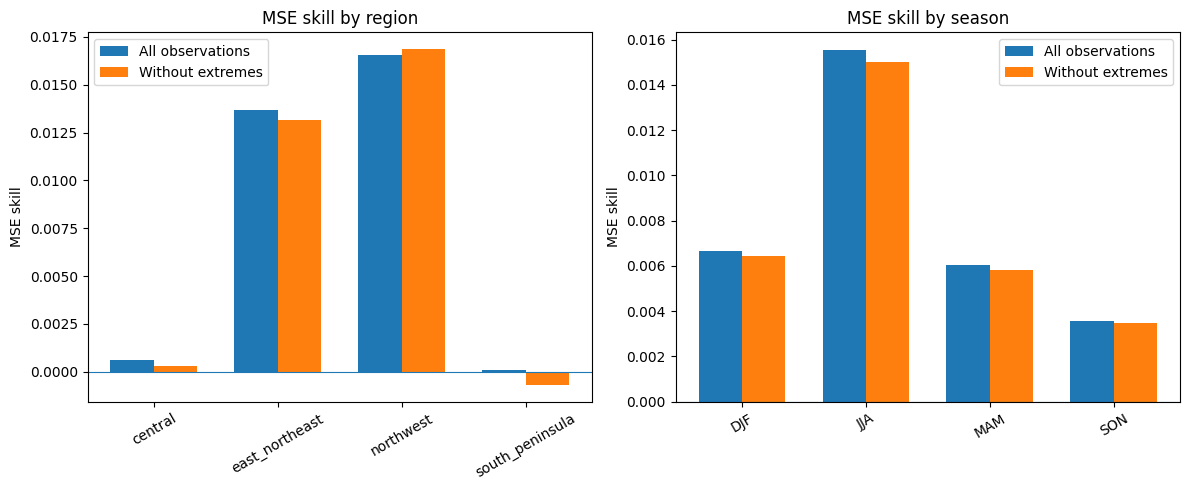

In [15]:
# create regional and seasonal performance graph
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, group_type in zip(axes, ["region", "season"]):
    names = [
        name for name in persistence_train_groups
        if name.startswith(group_type + "_")
    ]

    labels = [name.replace(group_type + "_", "") for name in names]

    all_scores = [
        persistence_train_groups[name]["all"]["mse_skill"]
        for name in names
    ]

    filtered_scores = [
        persistence_train_groups[name]["no_extremes"]["mse_skill"]
        for name in names
    ]

    x = np.arange(len(names))
    width = 0.35

    ax.bar(x - width / 2, all_scores, width, label="All observations")
    ax.bar(x + width / 2, filtered_scores, width, label="Without extremes")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30)
    ax.set_title(f"MSE skill by {group_type}")
    ax.set_ylabel("MSE skill")
    ax.axhline(0, linewidth=0.8)
    ax.legend()

plt.tight_layout()

# calculate dataset checksum if not already available
if "DATASET_MD5" not in globals():
    md5 = hashlib.md5()
    with open(DATA_PATH, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            md5.update(chunk)
    DATASET_MD5 = md5.hexdigest()

# log training run
mlflow.set_experiment("rain_v2_3month_persistence")

with mlflow.start_run(
    run_name="persistence_train",
    log_system_metrics=True
):
    mlflow.log_params({
        "model": "damped_persistence",
        "forecast_horizon_months": 3,
        "target": "target_z",
        "input_feature": "rain_z_t",
        "coefficient_method": "monthly_least_squares",
        "coefficient_constraint": "0_to_1",
        "training_period": "1901-2002",
        "sd_floor_mm": SD_FLOOR,
        "outlier_threshold": OUTLIER_THRESHOLD
    })

    for month, alpha in persistence_coefficients.items():
        mlflow.log_param(f"alpha_month_{month}", alpha)

    mlflow.set_tags({
        "model_type": "baseline",
        "baseline_method": "damped_persistence",
        "evaluation_split": "train",
        "git_commit": GIT_COMMIT,
        "dataset_md5": DATASET_MD5
    })

    # log overall metrics
    for subset, scores in persistence_train_metrics.items():
        for metric_name, value in scores.items():
            if np.isfinite(value):
                mlflow.log_metric(
                    f"train/{subset}/{metric_name}", float(value)
                )

    # log regional and seasonal metrics
    for group_name, results in persistence_train_groups.items():
        for subset, scores in results.items():
            for metric_name, value in scores.items():
                if np.isfinite(value):
                    mlflow.log_metric(
                        f"train/{group_name}/{subset}/{metric_name}",
                        float(value)
                    )

    # log graph
    with tempfile.TemporaryDirectory() as temp_dir:
        graph_path = os.path.join(temp_dir, "persistence_train.png")
        fig.savefig(graph_path, dpi=150, bbox_inches="tight")
        mlflow.log_artifact(graph_path, artifact_path="graphs")

plt.show()
plt.close(fig)

print("Damped persistence training run logged successfully.")

🏃 View run persistence_train at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/8/runs/5e319bc5f1494d118a3ba5a8ea0a5f52
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/8


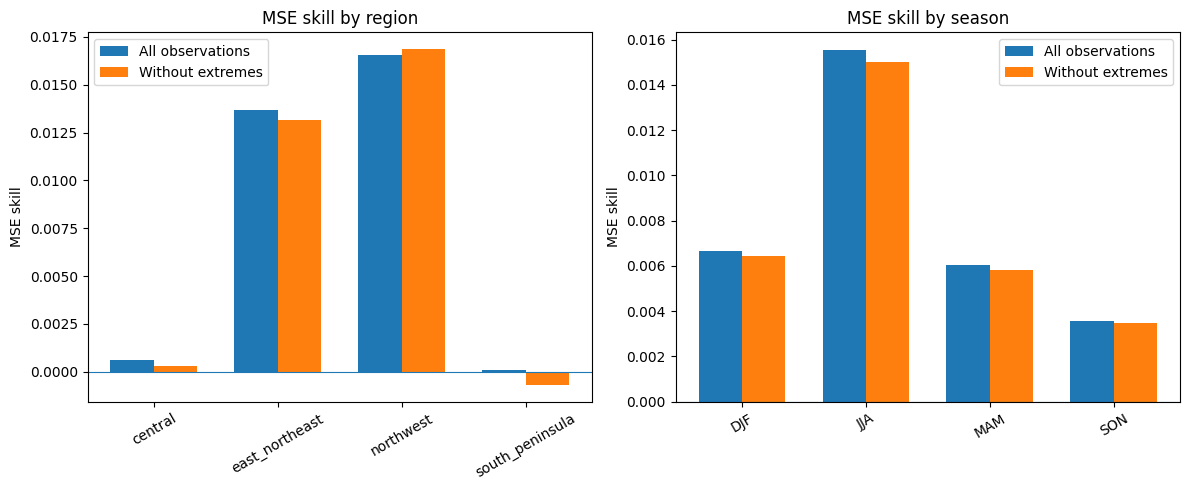

Training graph uploaded to the existing MLflow run.


In [16]:
# recreate the training performance graph
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, group_type in zip(axes, ["region", "season"]):
    names = [
        name for name in persistence_train_groups
        if name.startswith(group_type + "_")
    ]

    labels = [name.replace(group_type + "_", "") for name in names]

    all_scores = [
        persistence_train_groups[name]["all"]["mse_skill"]
        for name in names
    ]

    filtered_scores = [
        persistence_train_groups[name]["no_extremes"]["mse_skill"]
        for name in names
    ]

    x = np.arange(len(names))
    width = 0.35

    ax.bar(x - width / 2, all_scores, width, label="All observations")
    ax.bar(x + width / 2, filtered_scores, width, label="Without extremes")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30)
    ax.set_title(f"MSE skill by {group_type}")
    ax.set_ylabel("MSE skill")
    ax.axhline(0, linewidth=0.8)
    ax.legend()

plt.tight_layout()

# find the existing training run
experiment = mlflow.get_experiment_by_name(
    "rain_v2_3month_persistence"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.mlflow.runName = 'persistence_train'",
    order_by=["start_time DESC"],
    max_results=1
)

if runs.empty:
    raise ValueError("Persistence training run not found.")

run_id = runs.iloc[0]["run_id"]

# resume the existing run and upload only the graph
with tempfile.TemporaryDirectory() as temp_dir:
    graph_path = os.path.join(temp_dir, "persistence_train.png")
    fig.savefig(graph_path, dpi=150, bbox_inches="tight")

    with mlflow.start_run(run_id=run_id):
        mlflow.log_artifact(graph_path, artifact_path="graphs")

plt.show()
plt.close(fig)

print("Training graph uploaded to the existing MLflow run.")

In [17]:
# generate validation predictions using training coefficients
val_pred_persistence = (
    val_df["rain_z_t"].to_numpy()
    * val_df["month"].map(persistence_coefficients).to_numpy()
)

# calculate validation metrics
persistence_val_metrics = evaluate_model(
    val_df, val_pred_persistence
)

print("Validation predictions:", len(val_pred_persistence))
print("Validation metrics:")
display(pd.DataFrame(persistence_val_metrics).T)

Validation predictions: 632499
Validation metrics:


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,1.435939,0.019623,1.198307,0.834110,-0.018258,0.153402,0.019308,189.056764,104.545874,-1.715134,0.315914,-0.001894,632499.0
no_extremes,1.149828,0.015720,1.072300,0.808799,0.009663,0.129599,0.015681,180.955915,102.649838,0.509872,0.315517,-0.003049,630482.0


In [18]:
# calculate regional and seasonal validation metrics
persistence_val_groups = evaluate_by_group(
    val_df, val_pred_persistence
)

for group, result in persistence_val_groups.items():
    print(f"\n{group}")
    display(pd.DataFrame(result).T)


region_central


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,1.394023,0.013733,1.180688,0.802957,0.003308,0.123012,0.013731,194.619291,101.687823,-12.449855,0.302252,-0.050803,205524.0
no_extremes,1.062775,0.006380,1.030910,0.778755,0.029730,0.081192,0.005595,181.069500,99.244209,-9.760680,0.301805,-0.051983,204960.0



region_east_northeast


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,1.215433,0.023713,1.102467,0.847348,0.217894,0.156407,-0.019928,254.128591,148.809015,36.891295,0.290901,0.011869,102798.0
no_extremes,1.126817,0.023758,1.061516,0.840456,0.225647,0.151669,-0.026917,251.544244,148.129455,37.720912,0.290921,0.011626,102715.0



region_northwest


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,1.233228,0.014969,1.110508,0.801999,-0.040380,0.123087,0.013142,142.118174,84.686696,-1.656799,0.335944,0.027246,210657.0
no_extremes,1.103621,0.014991,1.050534,0.788172,-0.025097,0.122744,0.014049,136.147380,83.571683,-0.383037,0.335730,0.026793,210255.0


... (6 outputs left out)


season_MAM


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,1.793557,0.006663,1.339237,0.917350,-0.103537,0.084900,0.000606,259.922795,157.385937,-3.616374,0.309445,0.013777,161712.0
no_extremes,1.362559,0.004785,1.167287,0.878661,-0.060970,0.068766,0.002006,249.393421,154.018176,0.484192,0.310081,0.013169,160945.0



season_SON


,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss,n
all,1.079046,0.003014,1.038772,0.757172,0.140177,0.064661,-0.014310,85.309780,48.270309,4.309959,0.295382,-0.023791,151966.0
no_extremes,0.923078,0.002636,0.960770,0.742410,0.156625,0.065046,-0.023054,78.726978,47.426287,5.252777,0.294889,-0.024589,151681.0


- Persistence beats climatology on both training and validation.
- Its validation MSE skill is approximately 1.96%.
- The validation error is higher than training error, which is expected because validation contains unseen years.
- ACC is higher on validation, showing a somewhat stronger relationship between predictions and observations.
- Categorical (tercile accuracy)performance remains weak.

Regional Metrics:
- South Peninsula has the highest MSE skill (2.95%).
- East-Northeast comes next (2.37%).
- ACC is highest in South Peninsula, indicating a stronger relationship between predictions and actual anomalies.
- Tercile accuracy is still weak, particularly in East-Northeast.

Seasonal Metrics:
- JJA is clearly the strongest season.
- Persistence achieves approximately 6.4% MSE improvement during JJA.
- ACC is also much higher during JJA (0.299).
- DJF and SON show very little improvement.

Damped persistence achieves a modest improvement over climatology on validation data, with an overall MSE skill of approximately 1.96%. Its performance varies across regions and seasons. South Peninsula shows the highest regional improvement, while JJA shows the strongest seasonal performance, with an MSE skill of approximately 6.43% and ACC of 0.299. However, tercile accuracy remains relatively low, indicating limited ability to predict rainfall categories. 

This suggests that recent rainfall anomalies provide some predictive information, particularly during the monsoon season, but their overall contribution remains limited.

In [19]:
boot_data = val_df[
    ["key", "month", "year", "target_z", "target_anom_mm", "target_sd"]
].copy()

boot_data["pred_z"] = val_pred_persistence

boot_data = boot_data.merge(
    tercile_thresholds,
    on=["key", "month"],
    how="left",
    validate="many_to_one"
)

print("Bootstrap dataset prepared:", boot_data.shape)

Bootstrap dataset prepared: (632499, 9)


In [20]:
# prepare arrays for faster bootstrap calculations
z_true = boot_data["target_z"].to_numpy()
z_pred = boot_data["pred_z"].to_numpy()
anom_mm = boot_data["target_anom_mm"].to_numpy()
sd = boot_data["target_sd"].to_numpy()
lower = boot_data["lower_threshold"].to_numpy()
upper = boot_data["upper_threshold"].to_numpy()
years = boot_data["year"].to_numpy()

year_indices = {
    year: np.flatnonzero(years == year)
    for year in np.unique(years)
}

rng = np.random.default_rng(RANDOM_STATE)
bootstrap_scores = {"all": [], "no_extremes": []}

for _ in range(200):
    sampled_years = rng.choice(
        list(year_indices), size=len(year_indices), replace=True
    )

    indices = np.concatenate([
        year_indices[year] for year in sampled_years
    ])

    for name, selected in [
        ("all", indices),
        ("no_extremes", indices[
            np.abs(z_true[indices]) <= OUTLIER_THRESHOLD
        ])
    ]:
        scores = metrics(
            z_true[selected],
            z_pred[selected],
            anom_mm[selected],
            z_pred[selected] * sd[selected]
        )

        scores.update(categorical_metrics(
            z_true[selected],
            z_pred[selected],
            lower[selected],
            upper[selected]
        ))

        bootstrap_scores[name].append(scores)

# calculate 95% confidence intervals
persistence_bootstrap_ci = {}

for name, scores in bootstrap_scores.items():
    scores_df = pd.DataFrame(scores)

    persistence_bootstrap_ci[name] = pd.DataFrame({
        "lower_95": scores_df.quantile(0.025),
        "upper_95": scores_df.quantile(0.975)
    })

print("Bootstrap confidence intervals calculated.")

for name, ci in persistence_bootstrap_ci.items():
    print(f"\n{name}")
    display(ci)

Bootstrap confidence intervals calculated.

all


,lower_95,upper_95
mse,1.258009,1.589749
mse_skill,0.009508,0.028545
rmse_z,1.121610,1.260853
mae_z,0.801673,0.864537
bias_z,-0.086397,0.045260
acc,0.097585,0.204760
r2,0.007263,0.027192
rmse_mm,180.465701,195.534771
mae_mm,100.464082,109.384446
bias_mm,-11.372532,9.018976



no_extremes


,lower_95,upper_95
mse,1.057717,1.249550
mse_skill,0.006995,0.024202
rmse_z,1.028454,1.117832
mae_z,0.781977,0.836415
bias_z,-0.052329,0.068998
acc,0.084251,0.171287
r2,0.004774,0.023175
rmse_mm,172.485999,186.988674
mae_mm,98.206922,107.589519
bias_mm,-9.276299,11.414754


Overall conclusion
Damped persistence shows a small but positive improvement over climatology on validation data. Its continuous prediction performance is better than the reference baseline, but its ability to predict rainfall categories remains limited.

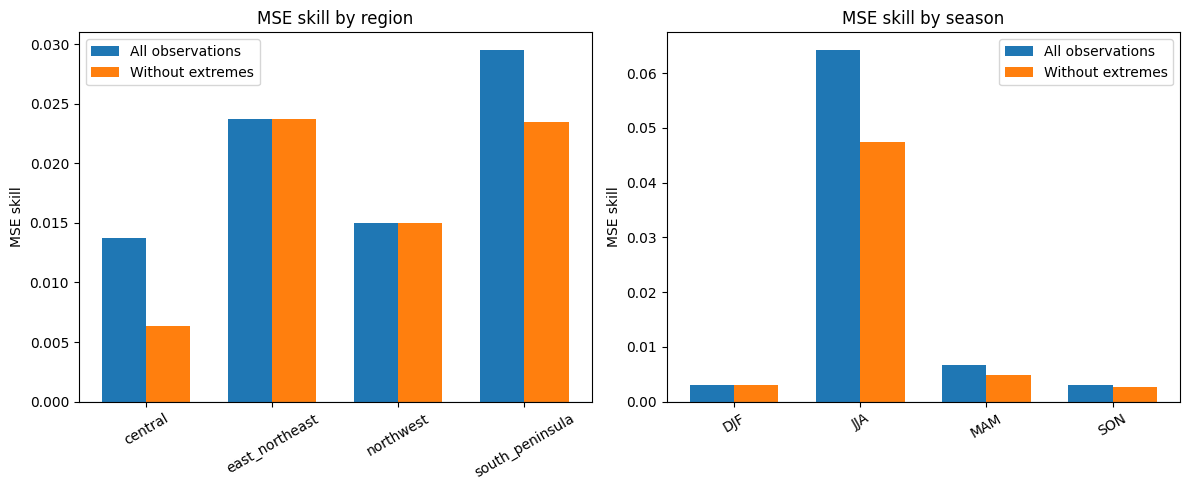

In [21]:
# create regional and seasonal validation graph
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, group_type in zip(axes, ["region", "season"]):
    names = [
        name for name in persistence_val_groups
        if name.startswith(group_type + "_")
    ]

    labels = [name.replace(group_type + "_", "") for name in names]

    all_scores = [
        persistence_val_groups[name]["all"]["mse_skill"]
        for name in names
    ]

    filtered_scores = [
        persistence_val_groups[name]["no_extremes"]["mse_skill"]
        for name in names
    ]

    x = np.arange(len(names))
    width = 0.35

    ax.bar(x - width / 2, all_scores, width, label="All observations")
    ax.bar(x + width / 2, filtered_scores, width, label="Without extremes")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30)
    ax.set_title(f"MSE skill by {group_type}")
    ax.set_ylabel("MSE skill")
    ax.axhline(0, linewidth=0.8)
    ax.legend()

plt.tight_layout()
plt.show()

In [22]:
# calculate dataset checksum if not already available
if "DATASET_MD5" not in globals():
    md5 = hashlib.md5()
    with open(DATA_PATH, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            md5.update(chunk)
    DATASET_MD5 = md5.hexdigest()

# log validation run
mlflow.set_experiment("rain_v2_3month_persistence")

with mlflow.start_run(
    run_name="persistence_validation",
    log_system_metrics=False
):
    mlflow.log_params({
        "model": "damped_persistence",
        "forecast_horizon_months": 3,
        "target": "target_z",
        "input_feature": "rain_z_t",
        "coefficient_method": "monthly_least_squares",
        "coefficient_constraint": "0_to_1",
        "training_period": "1901-2002",
        "validation_period": "2003-2013",
        "sd_floor_mm": SD_FLOOR,
        "outlier_threshold": OUTLIER_THRESHOLD,
        "bootstrap_repetitions": 200,
        "bootstrap_unit": "year"
    })

    for month, alpha in persistence_coefficients.items():
        mlflow.log_param(f"alpha_month_{month}", alpha)

    mlflow.set_tags({
        "model_type": "baseline",
        "baseline_method": "damped_persistence",
        "evaluation_split": "validation",
        "git_commit": GIT_COMMIT,
        "dataset_md5": DATASET_MD5
    })

    # log overall validation metrics
    for subset, scores in persistence_val_metrics.items():
        for metric_name, value in scores.items():
            if np.isfinite(value):
                mlflow.log_metric(
                    f"validation/{subset}/{metric_name}", float(value)
                )

    # log regional and seasonal metrics
    for group_name, results in persistence_val_groups.items():
        for subset, scores in results.items():
            for metric_name, value in scores.items():
                if np.isfinite(value):
                    mlflow.log_metric(
                        f"validation/{group_name}/{subset}/{metric_name}",
                        float(value)
                    )

    # log bootstrap confidence intervals
    for subset, ci in persistence_bootstrap_ci.items():
        for metric_name, row in ci.iterrows():
            if np.isfinite(row["lower_95"]) and np.isfinite(row["upper_95"]):
                mlflow.log_metric(
                    f"bootstrap/{subset}/{metric_name}/lower_95",
                    float(row["lower_95"])
                )
                mlflow.log_metric(
                    f"bootstrap/{subset}/{metric_name}/upper_95",
                    float(row["upper_95"])
                )

    # log validation graph
    with tempfile.TemporaryDirectory() as temp_dir:
        graph_path = os.path.join(
            temp_dir, "persistence_validation.png"
        )
        fig.savefig(graph_path, dpi=150, bbox_inches="tight")
        mlflow.log_artifact(graph_path, artifact_path="graphs")

plt.close(fig)

print("Damped persistence validation run logged successfully.")

🏃 View run persistence_validation at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/8/runs/ab0341d53cd94b949addeaeec7e90eb2
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/8


KeyboardInterrupt: 

In [23]:
client = mlflow.tracking.MlflowClient()

experiment = client.get_experiment_by_name(
    "rain_v2_3month_persistence"
)

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.mlflow.runName = 'persistence_validation'",
    max_results=1
)

persistence_val_run_id = runs[0].info.run_id

print("Existing validation run found:", persistence_val_run_id)

Existing validation run found: ab0341d53cd94b949addeaeec7e90eb2


Baseline Model 1: Ridge Regression

- Ridge Regression is selected because rainfall anomalies depend on multiple potentially correlated climate and geographical factors. 
- It can consider these factors together while using L2 regularisation to control large coefficients and reduce overfitting. 
- Its computationally efficienct and easily interprettable 

In [28]:
ridge_features = features.copy()

region_features = [
    "region_central",
    "region_east_northeast",
    "region_northwest",
    "region_south_peninsula"
]

assert len(ridge_features) == 23
assert all(feature in ridge_features for feature in region_features)

print("Total features:", len(ridge_features))
print("Regional features included:", len(region_features))

Total features: 23
Regional features included: 4


In [29]:
from sklearn.preprocessing import StandardScaler

continuous_features = [
    feature for feature in ridge_features
    if feature not in region_features
]

ridge_scaler = StandardScaler()

X_train_cont = ridge_scaler.fit_transform(
    train_df[continuous_features].to_numpy(dtype=np.float32)
).astype(np.float32)

X_train_region = train_df[region_features].to_numpy(dtype=np.float32)

X_train_ridge = np.column_stack([
    X_train_cont,
    X_train_region
]).astype(np.float32)

y_train_ridge = train_df["target_z"].to_numpy(dtype=np.float32)

print("Training input shape:", X_train_ridge.shape)
print("Training target shape:", y_train_ridge.shape)

Training input shape: (5980344, 23)
Training target shape: (5980344,)


Alpha controls the strength of L2 regularisation in Ridge Regression. It penalises large coefficients, helping reduce overfitting and improve model stability. We use an initial alpha of 1.0 and can tune it later through cross-validation.

LSQR is an iterative numerical solver used to estimate Ridge Regression coefficients. It is selected because it can efficiently handle our large training dataset without explicitly calculating a matrix inverse.

Alpha: Controls how strongly the model is regularised.

Solver: Controls how the model calculates its coefficients.

In [30]:
from sklearn.linear_model import Ridge
import time

ridge_model = Ridge(
    alpha=1.0,
    solver="lsqr"
)

start_time = time.time()

ridge_model.fit(X_train_ridge, y_train_ridge)

ridge_training_time = time.time() - start_time

print("Ridge model fitted successfully.")
print("Training time:", round(ridge_training_time, 2), "seconds")
print("Intercept:", ridge_model.intercept_)

Ridge model fitted successfully.
Training time: 1.0 seconds
Intercept: 0.00086947985


In [31]:
train_pred_ridge = ridge_model.predict(X_train_ridge)

ridge_train_metrics = evaluate_model(
    train_df,
    train_pred_ridge
)

print("Ridge training metrics:")
print(pd.DataFrame(ridge_train_metrics).T.round(4))

Ridge training metrics:
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          0.9765     0.0146  0.9882  0.7417  0.0000  0.1208  0.0146   
no_extremes  0.9444     0.0142  0.9718  0.7376  0.0046  0.1191  0.0142   

              rmse_mm   mae_mm  bias_mm  tercile_accuracy     hss          n  
all          162.7495  91.9315   0.0785            0.3359 -0.0089  5980344.0  
no_extremes  161.1597  91.6152   0.4558            0.3357 -0.0094  5976377.0  


What this tells us
- MSE skill = 0.0146: Ridge reduces training MSE by approximately 1.46% compared with climatology.
- ACC = 0.1208: It captures a weak positive relationship between predicted and observed anomalies.
- Bias ≈ 0: Predictions are not systematically overestimating or underestimating anomalies.
- Tercile accuracy = 33.59%: Only a small improvement over the one-third reference level.
- HSS is negative: It does not demonstrate useful categorical prediction skill yet.
Current conclusion: Ridge improves upon persistence on the training data, but the improvement is modest. Validation performance will tell us whether it generalises.

In [32]:
ridge_train_group_metrics = evaluate_by_group(
    train_df,
    train_pred_ridge
)

for group, values in ridge_train_group_metrics.items():
    print(f"\n{group}")
    print(pd.DataFrame(values).T.round(4))


region_central
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          0.9899     0.0000  0.9950  0.7403  0.0001  0.0571  0.0000   
no_extremes  0.9482    -0.0004  0.9737  0.7351  0.0059  0.0564 -0.0005   

              rmse_mm   mae_mm  bias_mm  tercile_accuracy     hss          n  
all          153.3888  88.1140   0.0612            0.3337 -0.0345  1940376.0  
no_extremes  152.4566  87.8917   0.3547            0.3334 -0.0352  1938811.0  

region_east_northeast
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          0.9713     0.0206  0.9855  0.7584 -0.0001  0.1450  0.0206   
no_extremes  0.9573     0.0198  0.9784  0.7565  0.0020  0.1417  0.0198   

              rmse_mm    mae_mm  bias_mm  tercile_accuracy     hss         n  
all          236.3130  133.1391   0.1462            0.3364  0.0101  985412.0  
no_extremes  233.6321  132.7344   0.5926            0.3363  0.0099  985104.0  

region_northwest
                mse  ms

Regional:
- Northwest: Best-performing region. Ridge captures some relationship between the input features and future rainfall anomalies here.
- East-Northeast: Some predictive ability, although weaker than Northwest.
- Central: Almost no improvement over climatology.
- South Peninsula: Very little improvement. Ridge struggles to capture useful predictive relationships here.

Seasonal:
- JJA (June–August): Strongest performance. Ridge captures more of the rainfall anomaly variation during this season.
- DJF: Some predictive ability, but considerably weaker than JJA.
- MAM and SON: Very limited predictive improvement.

Ridge Regression demonstrates modest improvement over climatology, with its strongest performance in the Northwest region and during the JJA season. Performance varies considerably across IMD regions, indicating that the relationships between the selected predictors and rainfall anomalies are not uniform across India. However, categorical prediction skill remains weak, and validation performance is required to determine whether these improvements generalise to unseen years.

In [35]:
print("Split values:")
print(df["split"].value_counts())

print("\nValidation dataframe shape:", val_df.shape)

val_df = df.loc[df["split"] == "val"].copy()

print("Validation rows:", len(val_df))

Split values:
split
train    5980344
test      693996
val       632499
Name: count, dtype: int64

Validation dataframe shape: (0, 34)
Validation rows: 632499


In [36]:
X_val_cont = ridge_scaler.transform(
    val_df[continuous_features].to_numpy(dtype=np.float32)
).astype(np.float32)

X_val_region = val_df[region_features].to_numpy(dtype=np.float32)

X_val_ridge = np.column_stack([
    X_val_cont,
    X_val_region
]).astype(np.float32)

y_val_ridge = val_df["target_z"].to_numpy(dtype=np.float32)

val_pred_ridge = ridge_model.predict(X_val_ridge)

print("Validation predictions generated.")
print("Validation input shape:", X_val_ridge.shape)
print("Prediction shape:", val_pred_ridge.shape)

Validation predictions generated.
Validation input shape: (632499, 23)
Prediction shape: (632499,)


In [37]:
ridge_val_metrics = evaluate_model(
    val_df,
    val_pred_ridge
)

print("Ridge validation metrics:")
print(pd.DataFrame(ridge_val_metrics).T.round(4))

Ridge validation metrics:
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          1.4309     0.0231  1.1962  0.8340 -0.0091  0.1535  0.0227   
no_extremes  1.1451     0.0198  1.0701  0.8087  0.0188  0.1415  0.0197   

              rmse_mm    mae_mm  bias_mm  tercile_accuracy     hss         n  
all          188.7839  104.3006  -1.0623            0.3181  0.0003  632499.0  
no_extremes  180.5917  102.3984   1.1702            0.3175 -0.0010  630482.0  


Ridge Regression achieves a validation MSE skill of 2.31% against climatology, showing a modest improvement over both climatology and damped persistence. It captures some variation in future rainfall anomalies, but its categorical prediction skill remains very limited. The similar performance across all observations and after excluding extreme anomalies suggests that its improvement is not solely driven by extreme events.

This is promising, but not yet strong enough to call it a reliable rainfall-category predictor.

In [38]:
ridge_val_group_metrics = evaluate_by_group(
    val_df,
    val_pred_ridge
)

for group, values in ridge_val_group_metrics.items():
    print(f"\n{group}")
    print(pd.DataFrame(values).T.round(4))


region_central
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          1.4066     0.0049   1.186  0.8074  0.0049  0.0782  0.0049   
no_extremes  1.0713    -0.0016   1.035  0.7830  0.0315  0.0587 -0.0024   

              rmse_mm    mae_mm  bias_mm  tercile_accuracy     hss         n  
all          196.6898  101.8161 -13.1990            0.3008 -0.0525  205524.0  
no_extremes  183.0043   99.3426 -10.4817            0.3006 -0.0534  204960.0  

region_east_northeast
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          1.1929     0.0418  1.0922  0.8364  0.2057  0.1985 -0.0011   
no_extremes  1.1053     0.0424  1.0513  0.8296  0.2134  0.1951 -0.0073   

              rmse_mm    mae_mm  bias_mm  tercile_accuracy     hss         n  
all          248.8455  146.5612  34.8000            0.2927  0.0147  102798.0  
no_extremes  246.2520  145.8846  35.6232            0.2927  0.0145  102715.0  

region_northwest
                mse  ms

Regional:

- East-Northeast: Best continuous prediction performance. It has the highest MSE skill and ACC. However, its tercile accuracy is low, so predicting the exact anomaly category remains difficult.
- Northwest: More balanced performance. It has the best categorical accuracy and HSS among the four regions.
- South Peninsula: Ridge achieves reasonable continuous skill, but has relatively high RMSE (1.439). This means prediction errors are still substantial.
- Central: Weakest region. MSE skill is almost zero, ACC is low and HSS is negative.

Seasonal: 
- JJA: Clearly the strongest season. Ridge captures considerably more rainfall anomaly variation during these months. Its categorical performance is also better than in other seasons.
- MAM: Small but positive improvement.
- SON: Very weak improvement, with negative HSS.
- DJF: Essentially no improvement over climatology.

Ridge Regression demonstrates varying predictive performance across India's IMD regions and seasons. Its strongest continuous prediction performance is observed in the East-Northeast region, while the Northwest region shows the best categorical prediction performance. Seasonally, JJA exhibits the highest predictive skill, suggesting that the selected rainfall history and climate predictors capture some useful relationships during the southwest monsoon. Central India and DJF remain particularly challenging. Overall, Ridge provides modest continuous predictive improvement, but categorical prediction skill remains limited across most groups.

In [39]:
ridge_boot_data = val_df[
    ["key", "month", "year", "target_z", "target_anom_mm", "target_sd"]
].copy()

ridge_boot_data["pred_z"] = val_pred_ridge

ridge_boot_data = ridge_boot_data.merge(
    tercile_thresholds,
    on=["key", "month"],
    how="left",
    validate="many_to_one"
)

print("Bootstrap data shape:", ridge_boot_data.shape)
print("Validation years:", ridge_boot_data["year"].nunique())

Bootstrap data shape: (632499, 9)
Validation years: 11


In [40]:
z_true = ridge_boot_data["target_z"].to_numpy()
z_pred = ridge_boot_data["pred_z"].to_numpy()
anom_mm = ridge_boot_data["target_anom_mm"].to_numpy()
sd = ridge_boot_data["target_sd"].to_numpy()
lower = ridge_boot_data["lower_threshold"].to_numpy()
upper = ridge_boot_data["upper_threshold"].to_numpy()
years = ridge_boot_data["year"].to_numpy()

year_indices = {
    year: np.flatnonzero(years == year)
    for year in np.unique(years)
}

rng = np.random.default_rng(RANDOM_STATE)

ridge_bootstrap_scores = {
    "all": [],
    "no_extremes": []
}

for _ in range(200):
    sampled_years = rng.choice(
        list(year_indices),
        size=len(year_indices),
        replace=True
    )

    indices = np.concatenate([
        year_indices[year] for year in sampled_years
    ])

    for name, selected in [
        ("all", indices),
        ("no_extremes", indices[np.abs(z_true[indices]) <= OUTLIER_THRESHOLD])
    ]:
        scores = {
            **metrics(
                z_true[selected],
                z_pred[selected],
                anom_mm[selected],
                z_pred[selected] * sd[selected]
            ),
            **categorical_metrics(
                z_true[selected],
                z_pred[selected],
                lower[selected],
                upper[selected]
            )
        }

        ridge_bootstrap_scores[name].append(scores)

ridge_bootstrap_ci = {}

for name, scores in ridge_bootstrap_scores.items():
    scores_df = pd.DataFrame(scores)

    ridge_bootstrap_ci[name] = pd.DataFrame({
        "lower_95": scores_df.quantile(0.025),
        "upper_95": scores_df.quantile(0.975)
    })

print("Ridge bootstrap confidence intervals calculated.")
print("\nMSE skill confidence intervals:")
for name, ci in ridge_bootstrap_ci.items():
    print(name, ci.loc["mse_skill"].round(4).to_dict())

Ridge bootstrap confidence intervals calculated.

MSE skill confidence intervals:
all {'lower_95': 0.0086, 'upper_95': 0.0345}
no_extremes {'lower_95': 0.0054, 'upper_95': 0.0337}


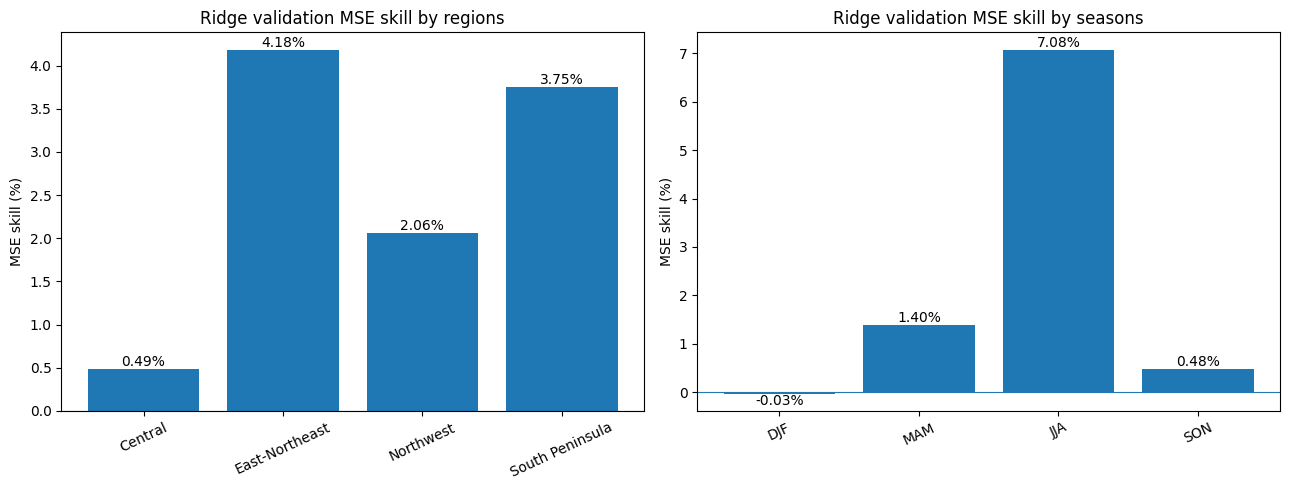

Graph saved: ../artifacts/ridge_validation.png
File size: 72.83 KB


In [41]:
from pathlib import Path

artifact_dir = Path("../artifacts")
artifact_dir.mkdir(exist_ok=True)

ridge_val_skill = {
    "regions": {
        "Central": ridge_val_group_metrics["region_central"]["all"]["mse_skill"],
        "East-Northeast": ridge_val_group_metrics["region_east_northeast"]["all"]["mse_skill"],
        "Northwest": ridge_val_group_metrics["region_northwest"]["all"]["mse_skill"],
        "South Peninsula": ridge_val_group_metrics["region_south_peninsula"]["all"]["mse_skill"]
    },
    "seasons": {
        "DJF": ridge_val_group_metrics["season_DJF"]["all"]["mse_skill"],
        "MAM": ridge_val_group_metrics["season_MAM"]["all"]["mse_skill"],
        "JJA": ridge_val_group_metrics["season_JJA"]["all"]["mse_skill"],
        "SON": ridge_val_group_metrics["season_SON"]["all"]["mse_skill"]
    }
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (group_name, values) in zip(axes, ridge_val_skill.items()):
    labels = list(values.keys())
    scores = np.array(list(values.values())) * 100

    bars = ax.bar(labels, scores)
    ax.axhline(0, linewidth=0.8)
    ax.set_title(f"Ridge validation MSE skill by {group_name}")
    ax.set_ylabel("MSE skill (%)")
    ax.tick_params(axis="x", rotation=25)

    for bar, score in zip(bars, scores):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            score,
            f"{score:.2f}%",
            ha="center",
            va="bottom" if score >= 0 else "top"
        )

fig.tight_layout()

ridge_val_graph_path = artifact_dir / "ridge_validation.png"
fig.savefig(ridge_val_graph_path, dpi=150, bbox_inches="tight")

plt.show()

assert ridge_val_graph_path.exists()
print("Graph saved:", ridge_val_graph_path)
print("File size:", round(ridge_val_graph_path.stat().st_size / 1024, 2), "KB")

In [43]:
import hashlib

dataset_md5 = hashlib.md5()

with open(DATA_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        dataset_md5.update(chunk)

dataset_md5 = dataset_md5.hexdigest()

print("Dataset MD5:", dataset_md5)

Dataset MD5: 8ea8f7473d958fb34548ab9e66dbff97


In [44]:
mlflow.set_experiment("rain_v2_3month_ridge")

with mlflow.start_run(run_name="ridge_validation", log_system_metrics=False) as run:

    mlflow.log_params({
        "model": "Ridge",
        "alpha": 1.0,
        "solver": "lsqr",
        "n_features": len(ridge_features),
        "n_bootstrap": 200
    })

    mlflow.set_tags({
        "stage": "validation",
        "model_type": "global_ridge",
        "git_commit": GIT_COMMIT,
        "dataset_md5": dataset_md5
    })

    for subset, values in ridge_val_metrics.items():
        for metric_name, value in values.items():
            if np.isfinite(value):
                mlflow.log_metric(f"{subset}_{metric_name}", value)

    for group, values in ridge_val_group_metrics.items():
        for subset, metrics_dict in values.items():
            for metric_name, value in metrics_dict.items():
                if np.isfinite(value):
                    mlflow.log_metric(
                        f"{group}_{subset}_{metric_name}", value
                    )

    for subset, ci in ridge_bootstrap_ci.items():
        for metric_name, row in ci.iterrows():
            mlflow.log_metric(
                f"{subset}_{metric_name}_ci_lower", row["lower_95"]
            )
            mlflow.log_metric(
                f"{subset}_{metric_name}_ci_upper", row["upper_95"]
            )

    mlflow.log_artifact(
        str(ridge_val_graph_path),
        artifact_path="graphs"
    )

print("Ridge validation metrics and graph logged successfully.")

🏃 View run ridge_validation at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/9/runs/fa59834ac7854276a9e010444e4b6836
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/9


KeyboardInterrupt: 

In [45]:
print("Graph exists:", ridge_val_graph_path.exists())
print("Graph size (KB):", round(ridge_val_graph_path.stat().st_size / 1024, 2))
print("Validation run ID:", run.info.run_id)

Graph exists: True
Graph size (KB): 72.83
Validation run ID: fa59834ac7854276a9e010444e4b6836


In [46]:
client = mlflow.tracking.MlflowClient()

client.log_artifact(
    run_id="fa59834ac7854276a9e010444e4b6836",
    local_path=str(ridge_val_graph_path),
    artifact_path="graphs"
)

print("Ridge validation graph uploaded.")

Ridge validation graph uploaded.


Baseline Model 2: LightGBM
- LightGBM is selected as a nonlinear machine learning approach to capture complex relationships and interactions between historical rainfall, climate indicators, seasonality and geographical features. 
- Its efficient tree-based learning makes it suitable for our large dataset. We will compare its predictive performance with Ridge Regression to determine whether capturing nonlinear patterns improves rainfall anomaly prediction.

In [47]:
try:
    import lightgbm as lgb
    print("LightGBM version:", lgb.__version__)
except ImportError:
    print("LightGBM is not installed.")

LightGBM version: 4.7.0


In [48]:
lightgbm_params = {
    "objective": "regression",
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 100,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 1.0,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "verbosity": -1
}

print(lightgbm_params)

{'objective': 'regression', 'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 31, 'max_depth': -1, 'min_child_samples': 100, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'random_state': 42, 'n_jobs': -1, 'verbosity': -1}


In [49]:
X_train_lgb = train_df[ridge_features].to_numpy(dtype=np.float32)
y_train_lgb = train_df["target_z"].to_numpy(dtype=np.float32)

print("Training input shape:", X_train_lgb.shape)
print("Training target shape:", y_train_lgb.shape)

Training input shape: (5980344, 23)
Training target shape: (5980344,)


In [50]:
lightgbm_model = lgb.LGBMRegressor(**lightgbm_params)

start_time = time.time()

lightgbm_model.fit(
    X_train_lgb,
    y_train_lgb
)

lightgbm_training_time = time.time() - start_time

print("LightGBM model fitted successfully.")
print("Training time:", round(lightgbm_training_time, 2), "seconds")
print("Number of trees:", lightgbm_model.n_estimators_)

LightGBM model fitted successfully.
Training time: 47.59 seconds
Number of trees: 300


In [51]:
train_pred_lgb = lightgbm_model.predict(X_train_lgb)

lgb_train_metrics = evaluate_model(
    train_df,
    train_pred_lgb
)

print("LightGBM training metrics:")
print(pd.DataFrame(lgb_train_metrics).T.round(4))

LightGBM training metrics:
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          0.7866     0.2062  0.8869  0.6587 -0.0000  0.4882  0.2062   
no_extremes  0.7607     0.2060  0.8722  0.6550  0.0041  0.4857  0.2059   

              rmse_mm   mae_mm  bias_mm  tercile_accuracy     hss          n  
all          152.2362  83.5368  -0.1197            0.4062  0.0990  5980344.0  
no_extremes  150.8483  83.2601   0.2123            0.4059  0.0984  5976377.0  



- MSE skill = 20.62%: LightGBM reduces training MSE by approximately 20.62% compared with climatology. That's a significant improvement over our previous baselines.
- ACC = 0.4882: It captures considerably more variation in observed rainfall anomalies.
- RMSE (z) = 0.8869: Prediction errors are lower than those of Ridge and persistence.
- Tercile accuracy = 40.62%: It correctly classifies substantially more observations into the three rainfall categories.
- HSS = 0.099: Unlike our previous models, LightGBM demonstrates positive categorical prediction skill.

LightGBM demonstrates substantial improvement over climatology, damped persistence and Ridge Regression on the training dataset. It achieves an MSE skill of 20.62%, an ACC of 0.4882 and a tercile accuracy of 40.62%. Its positive HSS also indicates improved categorical prediction ability. The similar results after excluding extreme anomalies suggest that its performance is not primarily driven by extreme observations. Validation evaluation is required to assess generalisation.

In [52]:
lgb_train_group_metrics = evaluate_by_group(
    train_df,
    train_pred_lgb
)

for group, values in lgb_train_group_metrics.items():
    print(f"\n{group}")
    print(pd.DataFrame(values).T.round(4))


region_central
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          0.7722     0.2200  0.8788  0.6471  0.0043  0.5191  0.2200   
no_extremes  0.7376     0.2217  0.8589  0.6424  0.0095  0.5182  0.2217   

              rmse_mm   mae_mm  bias_mm  tercile_accuracy     hss          n  
all          139.9548  78.5546   0.6477            0.4108  0.0883  1940376.0  
no_extremes  139.0206  78.3456   0.9206            0.4104  0.0875  1938811.0  

region_east_northeast
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          0.8573     0.1355  0.9259  0.7093 -0.0064  0.3903  0.1355   
no_extremes  0.8446     0.1352  0.9190  0.7075 -0.0044  0.3890  0.1352   

              rmse_mm    mae_mm  bias_mm  tercile_accuracy     hss         n  
all          228.6801  127.4237  -1.6491            0.3837  0.0798  985412.0  
no_extremes  226.2107  127.0437  -1.2297            0.3836  0.0796  985104.0  

region_northwest
                mse  ms

Regional:
- Northwest: Strongest performance across almost every metric. LightGBM captures rainfall anomaly patterns particularly well here.
- Central: Also performs strongly, with 22% MSE skill and ACC above 0.5.
- East-Northeast: Moderate improvement, but noticeably weaker than Central and Northwest.
- South Peninsula: Similar to East-Northeast, with positive continuous and categorical skill.

Seasonal:

- SON: Best continuous performance, with the highest MSE skill and tercile accuracy.
- DJF: Also performs very well, with almost identical ACC to SON.
- JJA: Strong categorical skill, with the highest HSS.
- MAM: Weakest season, but still achieves 15.2% MSE skill.

these are training results, and validation evaluation is necessary to determine whether the improvement generalises.

In [53]:
X_val_lgb = val_df[ridge_features].to_numpy(dtype=np.float32)

val_pred_lgb = lightgbm_model.predict(X_val_lgb)

print("Validation predictions generated.")
print("Validation input shape:", X_val_lgb.shape)
print("Prediction shape:", val_pred_lgb.shape)

Validation predictions generated.
Validation input shape: (632499, 23)
Prediction shape: (632499,)


In [54]:
lgb_val_metrics = evaluate_model(
    val_df,
    val_pred_lgb
)

print("LightGBM validation metrics:")
print(pd.DataFrame(lgb_val_metrics).T.round(4))

LightGBM validation metrics:
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          1.4207     0.0301  1.1919  0.8181 -0.0398  0.1778  0.0297   
no_extremes  1.1291     0.0335  1.0626  0.7925 -0.0117  0.1879  0.0334   

              rmse_mm    mae_mm  bias_mm  tercile_accuracy     hss         n  
all          187.2468  102.3583  -4.9362            0.3321  0.0196  632499.0  
no_extremes  178.7149  100.4197  -2.6859            0.3318  0.0186  630482.0  


But notice the difference:
- Training MSE skill: 20.62%
- Validation MSE skill: 3.01%
This is a substantial drop.

It suggests that LightGBM learns patterns very effectively from historical training data, but many of those patterns don't transfer as strongly to later years.

In [55]:
lgb_val_group_metrics = evaluate_by_group(val_df, val_pred_lgb)

for group, values in lgb_val_group_metrics.items():
    print(f"\n{group}")
    print(pd.DataFrame(values).T.round(4))


region_central
                mse  mse_skill  rmse_z   mae_z  bias_z    acc      r2  \
all          1.4102     0.0023  1.1875  0.7971 -0.0293  0.088  0.0023   
no_extremes  1.0674     0.0021  1.0331  0.7724 -0.0024  0.094  0.0013   

              rmse_mm    mae_mm  bias_mm  tercile_accuracy     hss         n  
all          196.8463  101.1300 -16.8343            0.3091 -0.0403  205524.0  
no_extremes  182.5994   98.6027 -14.0750            0.3091 -0.0409  204960.0  

region_east_northeast
                mse  mse_skill  rmse_z   mae_z  bias_z     acc      r2  \
all          1.1504      0.076  1.0726  0.8095  0.1395  0.2259  0.0347   
no_extremes  1.0595      0.082  1.0293  0.8024  0.1473  0.2329  0.0344   

              rmse_mm    mae_mm  bias_mm  tercile_accuracy     hss         n  
all          242.2901  141.4048  23.4552            0.3318  0.0526  102798.0  
no_extremes  239.5428  140.7133  24.2799            0.3319  0.0525  102715.0  

region_northwest
                mse  mse_s

Regional validation results
- East-Northeast: Best continuous skill (7.60%), ACC 0.226 and positive HSS (0.0526).
- Northwest: Good performance too, with 4.08% skill, ACC 0.210 and the highest tercile accuracy (35.13%).
- South Peninsula: Modest skill (2.74%), but the strongest negative bias (-0.2381), meaning it tends to underpredict anomalies.
- Central: Almost no useful skill (0.23%). HSS is negative (-0.0403), indicating poor categorical predictions.

Seasonal validation results
- JJA: Clearly the strongest season: 8.93% skill, ACC 0.312, tercile accuracy 38.00%, HSS 0.0924.
- MAM: Some skill (2.96%), with modest categorical performance.
- SON: Almost no skill (0.31%); HSS is negative.
- DJF: Negative skill (-0.93%), so LightGBM performs worse than the climatology reference here.

LightGBM shows uneven performance across regions and seasons.

In [56]:
lgb_val_group_path = "../artifacts/lightgbm_validation_groups.json"

with open(lgb_val_group_path, "w") as f:
    json.dump(lgb_val_group_metrics, f, indent=4)

print("Saved:", lgb_val_group_path)

Saved: ../artifacts/lightgbm_validation_groups.json


In [57]:
lgb_val_bootstrap = bootstrap_ci(
    val_df,
    val_pred_lgb,
    n_boot=200
)

display(lgb_val_bootstrap.round(4))

,lower_95,upper_95
mse,1.2549,1.5797
mse_skill,0.0114,0.0503
rmse_z,1.1202,1.2569
mae_z,0.7884,0.8492
bias_z,-0.1021,0.0102
acc,0.1274,0.2266
r2,0.0111,0.0499
rmse_mm,178.7352,194.8312
mae_mm,98.5881,106.9859
bias_mm,-13.0509,2.0618


In [58]:
client = mlflow.tracking.MlflowClient()

for experiment_name in [
    "rain_v2_3month_climatology",
    "rain_v2_3month_persistence",
    "rain_v2_3month_ridge",
    "rain_v2_3month_lightgbm"
]:
    experiment = client.get_experiment_by_name(experiment_name)
    print(f"\n{experiment_name}")

    if experiment:
        runs = client.search_runs(
            experiment_ids=[experiment.experiment_id],
            order_by=["attributes.start_time DESC"]
        )

        for run in runs:
            print(
                run.info.run_name,
                "|",
                run.info.run_id,
                "| metrics:",
                len(run.data.metrics)
            )


rain_v2_3month_climatology
climatology_validation | 742337b2546a4c38b28dc0de04a774db | metrics: 268
climatology_train | 0a9560e65cad4bd2b0c27dfa235ea370 | metrics: 224

rain_v2_3month_persistence
persistence_validation | ab0341d53cd94b949addeaeec7e90eb2 | metrics: 198
persistence_train | 5e319bc5f1494d118a3ba5a8ea0a5f52 | metrics: 203

rain_v2_3month_ridge
ridge_validation | fa59834ac7854276a9e010444e4b6836 | metrics: 78
ridge_validation | 082f2cee8389439281a9b309db74e1e5 | metrics: 0

rain_v2_3month_lightgbm


In [59]:
experiment = client.get_experiment_by_name(
    "rain_v2_3month_lightgbm"
)

print("Experiment:", experiment.experiment_id if experiment else "Not found")

if experiment:
    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id]
    )

    for run in runs:
        print(
            run.info.run_name,
            run.info.run_id,
            len(run.data.metrics)
        )

Experiment: Not found


In [61]:
from pathlib import Path

# output directory
artifact_dir = Path("../artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

# calculate training regional and seasonal metrics
lgb_train_group_metrics = evaluate_by_group(
    train_df,
    train_pred_lgb
)

# calculate overall validation confidence intervals
lgb_val_bootstrap = bootstrap_ci(
    val_df,
    val_pred_lgb,
    n_boot=200
)

# save metrics as json
def save_metrics_json(data, path):
    with open(path, "w") as f:
        json.dump(data, f, indent=4, default=str)

save_metrics_json(
    lgb_train_metrics,
    artifact_dir / "lightgbm_train_metrics.json"
)
save_metrics_json(
    lgb_val_metrics,
    artifact_dir / "lightgbm_validation_metrics.json"
)
save_metrics_json(
    lgb_train_group_metrics,
    artifact_dir / "lightgbm_train_groups.json"
)
save_metrics_json(
    lgb_val_group_metrics,
    artifact_dir / "lightgbm_validation_groups.json"
)
save_metrics_json(
    lgb_val_bootstrap.to_dict(),
    artifact_dir / "lightgbm_validation_bootstrap.json"
)

# metrics to visualise
plot_metrics = [
    "mse_skill",
    "rmse_z",
    "mae_z",
    "acc",
    "tercile_accuracy",
    "hss"
]

# overall training vs validation graphs
for metric in plot_metrics:
    fig, ax = plt.subplots(figsize=(6, 4))

    values = [
        lgb_train_metrics["all"][metric],
        lgb_val_metrics["all"][metric]
    ]

    ax.bar(["Training", "Validation"], values)
    ax.set_title(f"LightGBM overall {metric}")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()
    fig.savefig(
        artifact_dir / f"lightgbm_overall_{metric}.png",
        dpi=150
    )
    plt.close(fig)

# regional and seasonal validation graphs
for group_type in ["region", "season"]:
    group_data = (
        lgb_val_group_metrics
        if group_type == "region"
        else lgb_val_group_metrics
    )

    for metric in plot_metrics:
        labels = []
        values = []

        for group, results in group_data.items():
            if group.startswith(group_type + "_"):
                labels.append(group.replace(group_type + "_", "").replace("_", " ").title())
                values.append(results["all"][metric])

        fig, ax = plt.subplots(figsize=(7, 4))
        ax.bar(labels, values)
        ax.set_title(f"LightGBM validation {group_type}: {metric}")
        ax.set_ylabel(metric)
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.3)

        fig.tight_layout()
        fig.savefig(
            artifact_dir / f"lightgbm_validation_{group_type}_{metric}.png",
            dpi=150
        )
        plt.close(fig)

print("LightGBM results and graphs saved.")
print("Files saved:", len(list(artifact_dir.glob("lightgbm_*"))))
display(lgb_val_bootstrap.round(4))

LightGBM results and graphs saved.
Files saved: 23


,lower_95,upper_95
mse,1.2549,1.5797
mse_skill,0.0114,0.0503
rmse_z,1.1202,1.2569
mae_z,0.7884,0.8492
bias_z,-0.1021,0.0102
acc,0.1274,0.2266
r2,0.0111,0.0499
rmse_mm,178.7352,194.8312
mae_mm,98.5881,106.9859
bias_mm,-13.0509,2.0618


In [ ]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

experiment = mlflow.set_experiment("rain_v2_3month_lightgbm")
experiment_id = experiment.experiment_id

# refresh the git commit tag
GIT_COMMIT = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"],
    text=True
).strip()

# dataset fingerprint
dataset_md5 = hashlib.md5(
    Path(DATA_PATH).read_bytes()
).hexdigest()

def flatten_group_metrics(group_metrics):
    flattened = {}

    for group, results in group_metrics.items():
        for subset, metric_values in results.items():
            for metric, value in metric_values.items():
                if isinstance(value, (int, float, np.integer, np.floating)):
                    if np.isfinite(value):
                        flattened[f"{group}_{subset}_{metric}"] = float(value)

    return flattened


def log_lightgbm_run(
    run_name,
    overall_metrics,
    group_metrics,
    split
):
    with mlflow.start_run(
        experiment_id=experiment_id,
        run_name=run_name,
        log_system_metrics=False
    ) as run:

        mlflow.log_params(lightgbm_params)

        mlflow.set_tags({
            "model": "LightGBM",
            "split": split,
            "dataset_version": "rain_v2_3month_dataset_02",
            "git_commit": GIT_COMMIT,
            "dataset_md5": dataset_md5
        })

        # overall metrics
        overall_flat = {}

        for subset, values in overall_metrics.items():
            for metric, value in values.items():
                if isinstance(value, (int, float, np.integer, np.floating)):
                    if np.isfinite(value):
                        overall_flat[f"{subset}_{metric}"] = float(value)

        # regional and seasonal metrics
        group_flat = flatten_group_metrics(group_metrics)

        mlflow.log_metrics({
            **overall_flat,
            **group_flat
        })

        return run.info.run_id


# create training and validation runs
lgb_train_run_id = log_lightgbm_run(
    "lightgbm_train",
    lgb_train_metrics,
    lgb_train_group_metrics,
    "train"
)

lgb_val_run_id = log_lightgbm_run(
    "lightgbm_validation",
    lgb_val_metrics,
    lgb_val_group_metrics,
    "validation"
)



2026/11/12 04:34:45 INFO mlflow.tracking.fluent: Experiment with name 'rain_v2_3month_lightgbm' does not exist. Creating a new experiment.


🏃 View run lightgbm_train at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/10/runs/f11e859b8258403ab12f99199c095f4a
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/10
🏃 View run lightgbm_validation at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/10/runs/e962006735124fbf97478b5cb9e6f38a
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/10


AttributeError: 'MlflowClient' object has no attribute 'log_metrics'

In [63]:
from mlflow.entities import Metric
# log validation bootstrap confidence intervals
bootstrap_metrics = {}

bootstrap_metric_objects = [
    Metric(
        key=key,
        value=value,
        timestamp=int(time.time() * 1000),
        step=0
    )
    for key, value in bootstrap_metrics.items()
]

client.log_batch(
    run_id=lgb_val_run_id,
    metrics=bootstrap_metric_objects
)

# upload saved artifacts directly
for run_id, prefix in [
    (lgb_train_run_id, "lightgbm_train"),
    (lgb_val_run_id, "lightgbm_")
]:
    for path in artifact_dir.glob(f"{prefix}*"):
        client.log_artifact(
            run_id,
            str(path),
            artifact_path="results"
        )

print("Training run:", lgb_train_run_id)
print("Validation run:", lgb_val_run_id)
print("LightGBM metrics and artifacts logged.")

Training run: f11e859b8258403ab12f99199c095f4a
Validation run: e962006735124fbf97478b5cb9e6f38a
LightGBM metrics and artifacts logged.


In [64]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

model_runs = {
    "Climatology": ("rain_v2_3month_climatology", "climatology_validation"),
    "Persistence": ("rain_v2_3month_persistence", "persistence_validation"),
    "Ridge": ("rain_v2_3month_ridge", "ridge_validation"),
    "LightGBM": ("rain_v2_3month_lightgbm", "lightgbm_validation")
}

validation_metrics = {}

for model_name, (experiment_name, run_name) in model_runs.items():
    experiment = client.get_experiment_by_name(experiment_name)

    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        filter_string=f"tags.mlflow.runName = '{run_name}'"
    )

    if not runs:
        raise ValueError(f"Missing run: {run_name}")

    run = max(runs, key=lambda r: r.info.start_time)
    validation_metrics[model_name] = run.data.metrics

    print(model_name, ":", len(run.data.metrics), "metrics retrieved")

Climatology : 268 metrics retrieved
Persistence : 198 metrics retrieved
Ridge : 78 metrics retrieved
LightGBM : 234 metrics retrieved


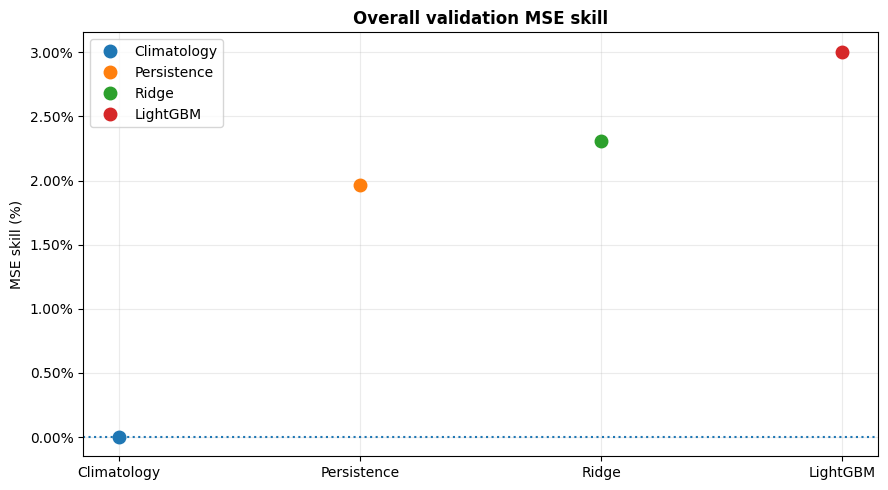

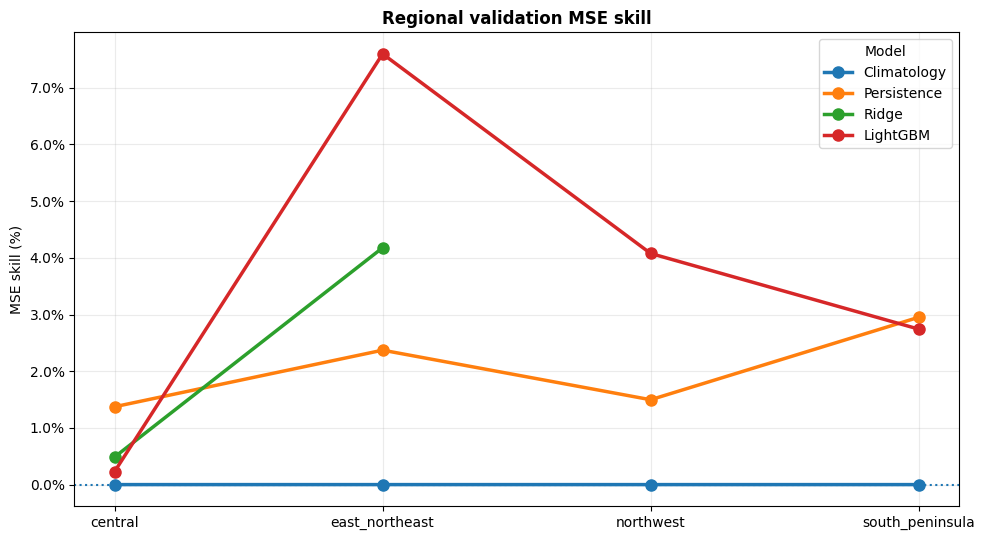

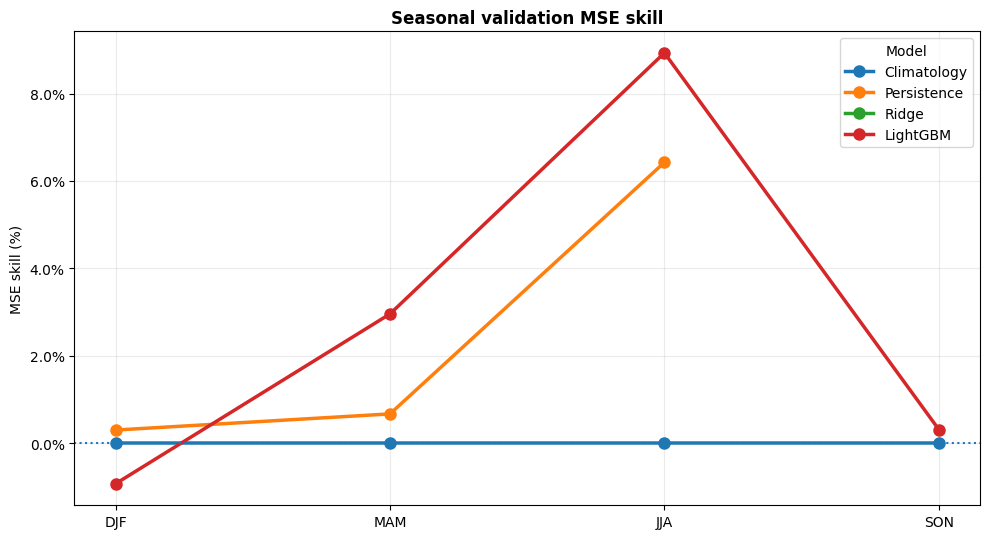

Three MSE skill comparison graphs saved.


In [68]:
import matplotlib.ticker as mtick
from pathlib import Path

comparison_dir = Path("../artifacts/model_comparisons")
comparison_dir.mkdir(parents=True, exist_ok=True)

models = ["Climatology", "Persistence", "Ridge", "LightGBM"]

regions = [
    "central",
    "east_northeast",
    "northwest",
    "south_peninsula"
]

seasons = ["DJF", "MAM", "JJA", "SON"]


def get_skill(model, group_type=None, group=None):
    data = validation_metrics[model]

    if model in ["Climatology", "Persistence"]:
        if group_type is None:
            key = "validation/all/mse_skill"
        else:
            key = f"validation/{group_type}_{group}/all/mse_skill"
    else:
        if group_type is None:
            key = "all_mse_skill"
        else:
            key = f"{group_type}_{group}_all_mse_skill"

    return data.get(key, np.nan) * 100


# overall comparison
fig, ax = plt.subplots(figsize=(9, 5))

for model in models:
    ax.plot(
        [model],
        [get_skill(model)],
        marker="o",
        markersize=9,
        linestyle="none",
        label=model
    )

ax.axhline(0, linestyle=":", linewidth=1.5)
ax.set_title("Overall validation MSE skill", weight="bold")
ax.set_ylabel("MSE skill (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(comparison_dir / "overall_mse_skill.png", dpi=180)
plt.show()
plt.close(fig)


# regional and seasonal comparison
def plot_group_skill(title, groups, group_type):
    fig, ax = plt.subplots(figsize=(10, 5.5))

    for model in models:
        values = [
            get_skill(model, group_type, group)
            for group in groups
        ]

        ax.plot(
            groups,
            values,
            marker="o",
            linewidth=2.5,
            markersize=8,
            label=model
        )

    ax.axhline(0, linestyle=":", linewidth=1.5)
    ax.set_title(title, weight="bold")
    ax.set_ylabel("MSE skill (%)")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.grid(alpha=0.25)
    ax.legend(title="Model")
    fig.tight_layout()

    filename = f"{group_type}_mse_skill.png"
    fig.savefig(comparison_dir / filename, dpi=180)
    plt.show()
    plt.close(fig)


plot_group_skill(
    "Regional validation MSE skill",
    regions,
    "region"
)

plot_group_skill(
    "Seasonal validation MSE skill",
    seasons,
    "season"
)

print("Three MSE skill comparison graphs saved.")

In [67]:
for model, metrics_dict in validation_metrics.items():
    print(f"\n{model}")
    print([
        key for key in metrics_dict
        if "mse_skill" in key
    ])


Climatology
['validation/season_DJF/all/mse_skill', 'validation/season_DJF/no_extremes/mse_skill', 'validation/season_SON/all/mse_skill', 'validation/region_south_peninsula/all/mse_skill', 'validation/region_east_northeast/all/mse_skill', 'validation/no_extremes/mse_skill', 'validation/region_south_peninsula/no_extremes/mse_skill', 'validation/region_central/no_extremes/mse_skill', 'validation/season_JJA/no_extremes/mse_skill', 'validation/season_MAM/no_extremes/mse_skill', 'validation/region_east_northeast/no_extremes/mse_skill', 'validation/season_JJA/all/mse_skill', 'bootstrap/no_extremes/mse_skill/upper_95', 'validation/region_northwest/all/mse_skill', 'bootstrap/all/mse_skill/upper_95', 'validation/region_northwest/no_extremes/mse_skill', 'validation/season_SON/no_extremes/mse_skill', 'bootstrap/no_extremes/mse_skill/lower_95', 'validation/region_central/all/mse_skill', 'validation/all/mse_skill', 'validation/season_MAM/all/mse_skill', 'bootstrap/all/mse_skill/lower_95']

Persist

In [69]:
comparison_files = [
    "overall_mse_skill.png",
    "region_mse_skill.png",
    "season_mse_skill.png"
]

for filename in comparison_files:
    path = comparison_dir / filename

    client.log_artifact(
        run_id=lgb_val_run_id,
        local_path=str(path),
        artifact_path="model_comparisons"
    )

print("Three comparison graphs uploaded successfully.")

Three comparison graphs uploaded successfully.


In [70]:
# restore ridge regional and seasonal metrics from notebook results

ridge_group_metrics = ridge_val_group_metrics

print("Ridge regional and seasonal groups:")
for group, values in ridge_group_metrics.items():
    print(group, values["all"]["mse_skill"])

Ridge regional and seasonal groups:
region_central 0.0048670173
region_east_northeast 0.041779995
region_northwest 0.02063334
region_south_peninsula 0.037503123
season_DJF -0.0002721548
season_JJA 0.07076681
season_MAM 0.013950169
season_SON 0.0048137307


In [72]:
print("Persistence group metric variables:")

for name in globals():
    if "persistence" in name.lower() and "group" in name.lower():
        print(name)

Persistence group metric variables:
persistence_train_groups
persistence_val_groups


In [73]:
for name in [
    "persistence_val_groups",
    "ridge_val_group_metrics",
    "lgb_val_group_metrics"
]:
    print(f"\n{name}")
    for group, values in globals()[name].items():
        print(group, values["all"]["mse_skill"])


persistence_val_groups
region_central 0.01373344640226526
region_east_northeast 0.02371316826175962
region_northwest 0.014969336061079086
region_south_peninsula 0.029512463138002043
season_DJF 0.0029671560263627716
season_JJA 0.06426169525183045
season_MAM 0.006663263707818334
season_SON 0.0030141701488052286

ridge_val_group_metrics
region_central 0.0048670173
region_east_northeast 0.041779995
region_northwest 0.02063334
region_south_peninsula 0.037503123
season_DJF -0.0002721548
season_JJA 0.07076681
season_MAM 0.013950169
season_SON 0.0048137307

lgb_val_group_metrics
region_central 0.002304132415669735
region_east_northeast 0.07597939378218344
region_northwest 0.040771554228953844
region_south_peninsula 0.027430512973423027
season_DJF -0.009326809029431393
season_JJA 0.0893391680596638
season_MAM 0.029560270475002204
season_SON 0.0030877360628329686


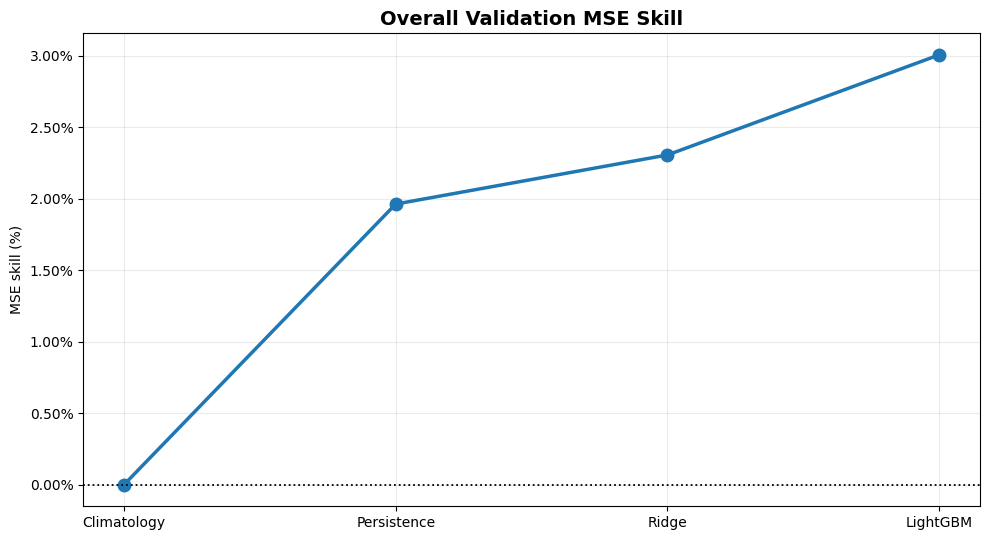

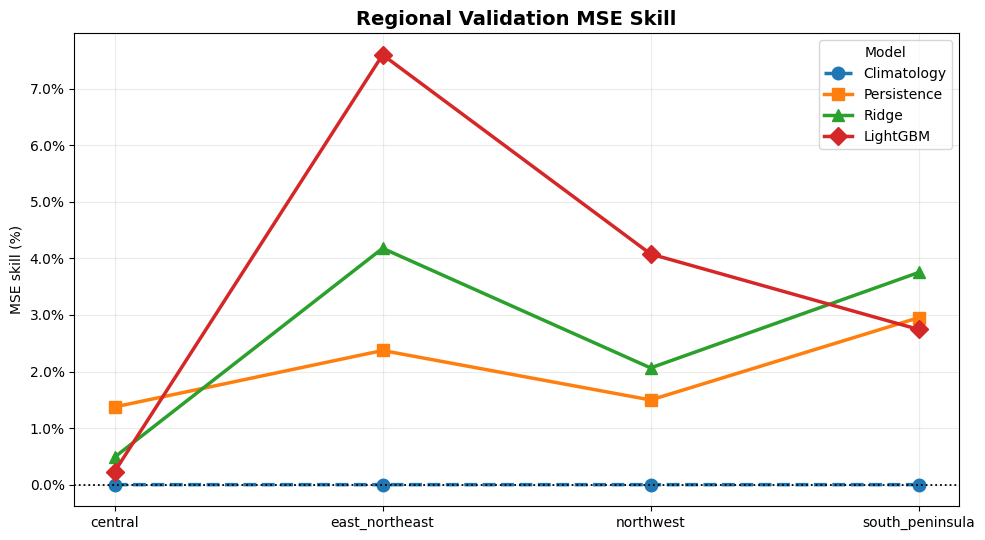

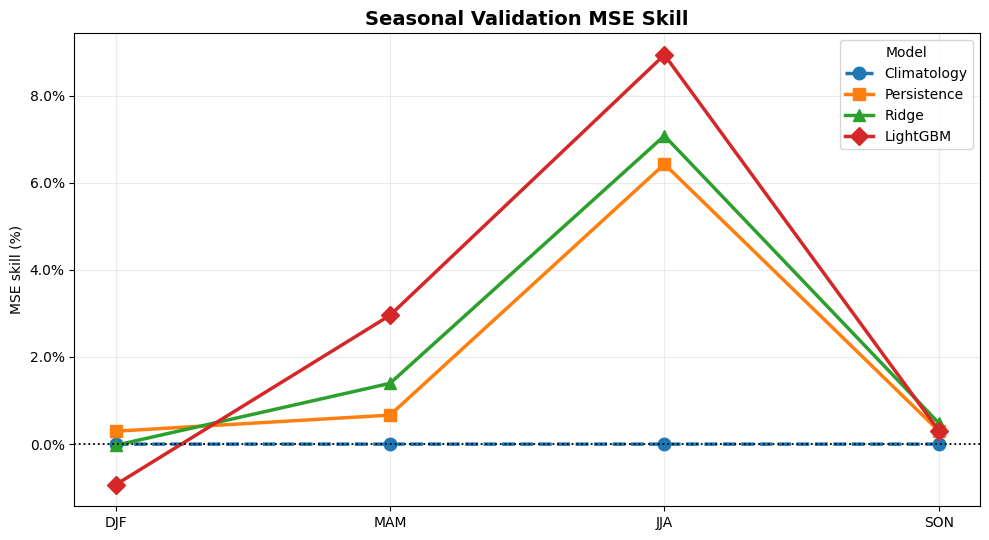

In [75]:
import matplotlib.ticker as mtick

styles = {
    "Climatology": ("o", "--"),
    "Persistence": ("s", "-"),
    "Ridge": ("^", "-"),
    "LightGBM": ("D", "-")
}

def plot_skill_comparison(title, groups, group_type=None):
    fig, ax = plt.subplots(figsize=(10, 5.5))

    if group_type is None:
        # overall: models are the x-axis categories
        values = [overall_skill[model] * 100 for model in models]

        ax.plot(
            models,
            values,
            marker="o",
            linewidth=2.5,
            markersize=9
        )

    else:
        # regional and seasonal: each model gets its own line
        for model in models:
            values = [
                group_results[model][f"{group_type}_{group}"]["all"]["mse_skill"] * 100
                for group in groups
            ]

            marker, linestyle = styles[model]

            ax.plot(
                groups,
                values,
                label=model,
                marker=marker,
                linestyle=linestyle,
                linewidth=2.5,
                markersize=9
            )

        ax.legend(title="Model")

    ax.axhline(0, color="black", linestyle=":", linewidth=1.3)
    ax.set_title(title, fontsize=14, weight="bold")
    ax.set_ylabel("MSE skill (%)")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.grid(alpha=0.25)
    fig.tight_layout()

    filename = {
        None: "overall_validation_mse_skill.png",
        "region": "regional_validation_mse_skill.png",
        "season": "seasonal_validation_mse_skill.png"
    }[group_type]

    fig.savefig(comparison_dir / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_skill_comparison("Overall Validation MSE Skill", models)
plot_skill_comparison("Regional Validation MSE Skill", regions, "region")
plot_skill_comparison("Seasonal Validation MSE Skill", seasons, "season")

In [76]:
for filename in [
    "regional_validation_mse_skill.png",
    "seasonal_validation_mse_skill.png"
]:
    client.log_artifact(
        run_id=lgb_val_run_id,
        local_path=str(comparison_dir / filename),
        artifact_path="model_comparisons"
    )

print("Regional and seasonal comparison graphs uploaded.")

Regional and seasonal comparison graphs uploaded.


The below code is a paired year-block bootstrap. It resamples the 11 val years many times (the same years for both models each time) and measures how much better LightGBM is than Ridge in MSE skill against climatology. We ran it to test whether LightGBM is really better than Ridge, or only looks better by chance.

In [86]:
import numpy as np

# Ridge name is a guess: change it if the check below says it is missing
RIDGE_NAME = "val_pred_ridge"

if RIDGE_NAME not in globals():
    print(f"{RIDGE_NAME} not found. Variables with 'pred' in the name:")
    print([n for n in globals() if "pred" in n.lower()])
else:
    p_a = np.asarray(val_pred_lgb, float)
    p_b = np.asarray(globals()[RIDGE_NAME], float)

    # checks before the bootstrap
    print("rows val_df:", len(val_df), "| lgb:", len(p_a), "| ridge:", len(p_b))
    assert len(val_df) == len(p_a) == len(p_b), "length mismatch, stop"
    print("val_df has year and target_z:", {"year", "target_z"} <= set(val_df.columns))
    print("val years:", sorted(val_df["year"].unique()))

    # sanity: recompute MSE skill of each model, compare with your tables
    y = val_df["target_z"].to_numpy(float)
    for nm, p in [("LightGBM", p_a), ("Ridge", p_b)]:
        print(nm, "MSE skill (all rows):", round(1 - ((y - p) ** 2).sum() / (y ** 2).sum(), 4))

    for name, cut in [("all rows", None), ("|z|<=6 only", OUTLIER_THRESHOLD)]:
        res, per_year = paired_year_bootstrap(val_df["year"], y, p_a, p_b, drop_extreme=cut)
        print(f"\n{name}:", res)
        print(per_year.to_string())

rows val_df: 632499 | lgb: 632499 | ridge: 632499
val_df has year and target_z: True
val years: [np.int16(2003), np.int16(2004), np.int16(2005), np.int16(2006), np.int16(2007), np.int16(2008), np.int16(2009), np.int16(2010), np.int16(2011), np.int16(2012), np.int16(2013)]
LightGBM MSE skill (all rows): 0.0301
Ridge MSE skill (all rows): 0.0231

all rows: {'years': 11, 'skill_A': np.float64(0.0301), 'skill_B': np.float64(0.0231), 'diff_A_minus_B': np.float64(0.007), 'diff_lower_95': -0.0106, 'diff_upper_95': 0.0229, 'share_A_better': 0.798}
      skill_A  skill_B  A_minus_B
year                             
2003   0.0370   0.0251     0.0119
2004   0.0097   0.0023     0.0074
2005   0.0087   0.0237    -0.0150
2006   0.0711   0.0196     0.0515
2007   0.0017  -0.0001     0.0018
2008   0.0084  -0.0143     0.0227
2009  -0.0226   0.0459    -0.0685
2010   0.0452   0.0452     0.0000
2011   0.0823   0.0478     0.0345
2012   0.0576   0.0450     0.0126
2013   0.0135   0.0160    -0.0025

|z|<=6 only

Output Interpretation:

The checks passed. Row counts match, and the recomputed skills (3.01% and 2.31%) match your tables, so the row order is correct.
All rows: LightGBM leads by 0.7 points. The 95% range for the difference is -1.1 to +2.3, which includes 0. LightGBM was better in 80% of resamples.
Without extremes (|z| ≤ 6): the lead is 1.4 points, range -0.8 to +3.4, which also includes 0. LightGBM was better in 89% of resamples.
Per year, LightGBM wins in 7 of 11 years (6 of 11 without extremes). It loses clearly in 2009, which is an El Nino monsoon year, and in 2005.

LightGBM and Ridge are statistically similar on val. LightGBM was chosen because it has the best point estimate, the best skill in JJA, east_northeast and northwest, the best ACC and HSS, and more room to improve with tuning.


In [87]:
#saving predictinon output values to a file
import numpy as np
import pandas as pd

need = ["key", "year", "month", "region", "split",
        "target_z", "target_mm", "target_mean", "target_sd"]
missing = [c for c in need if c not in val_df.columns]
assert not missing, f"val_df lacks {missing}. Its columns are: {list(val_df.columns)}"

p_lgb = np.asarray(val_pred_lgb, float)
p_rdg = np.asarray(val_pred_ridge, float)
assert len(val_df) == len(p_lgb) == len(p_rdg), "length mismatch, stop"

out = val_df[need].copy().reset_index(drop=True)
out["region"] = out["region"].astype(str)
out["pred_z_lgbm"] = p_lgb
out["pred_z_ridge"] = p_rdg
for m in ["lgbm", "ridge"]:
    out[f"pred_anom_mm_{m}"] = out[f"pred_z_{m}"] * out["target_sd"]
    out[f"pred_total_mm_{m}"] = out["target_mean"] + out[f"pred_anom_mm_{m}"]

# checks
y = out["target_z"].to_numpy(float)
for m in ["lgbm", "ridge"]:
    p = out[f"pred_z_{m}"].to_numpy(float)
    print(m, "MSE skill (all rows):", round(1 - ((y - p) ** 2).sum() / (y ** 2).sum(), 4))
print("splits:", out["split"].unique().tolist())
print("duplicate (key, year, month):", int(out.duplicated(["key", "year", "month"]).sum()))
print("NaN in prediction columns:", int(out.filter(like="pred_").isna().sum().sum()))
print("rows:", len(out), "| years:", sorted(out["year"].unique().tolist()))

path = PROCESSED / "rain_v2_3month_val_predictions.parquet"
assert not path.exists(), "file exists, use a new name"
out.to_parquet(path, index=False)
print("saved:", path, "| MB:", round(path.stat().st_size / 1e6, 1))
print(out.head(3).round(3).to_string(index=False))

lgbm MSE skill (all rows): 0.0301
ridge MSE skill (all rows): 0.0231
splits: ['val']
duplicate (key, year, month): 0
NaN in prediction columns: 0
rows: 632499 | years: [2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]


NameError: name 'PROCESSED' is not defined

In [88]:
from pathlib import Path

PROCESSED = Path(DATA_PATH).parent          # ../data/processed
path = PROCESSED / "rain_v2_3month_val_predictions.parquet"
assert not path.exists(), "file exists, use a new name"

out.to_parquet(path, index=False)
print("saved:", path, "| MB:", round(path.stat().st_size / 1e6, 1))
print(out.head(3).round(3).to_string(index=False))

saved: ../data/processed/rain_v2_3month_val_predictions.parquet | MB: 37.7
    key  year  month          region split  target_z  target_mm  target_mean  target_sd  pred_z_lgbm  pred_z_ridge  pred_anom_mm_lgbm  pred_total_mm_lgbm  pred_anom_mm_ridge  pred_total_mm_ridge
8257700  2003      1 south_peninsula   val    -1.499  49.799000   171.242004  80.990997       -0.492        -0.274            -39.816             131.426             -22.160              149.082
8257700  2003      2 south_peninsula   val    -1.685  78.449997   306.183990 135.173996       -0.396        -0.199            -53.528             252.656             -26.912              279.273
8257700  2003      3 south_peninsula   val    -1.900 103.560997   499.472992 208.429001       -0.400        -0.165            -83.290             416.182             -34.436              465.037


In [89]:
import hashlib, tempfile, os
import mlflow

RUN_NAME = "rain_v2_lgbm_vs_ridge_paired"
mlflow.set_experiment(EXPERIMENTS["lightgbm"])
exp = mlflow.get_experiment_by_name(EXPERIMENTS["lightgbm"])
prev = mlflow.search_runs(experiment_ids=[exp.experiment_id],
                          filter_string=f"tags.mlflow.runName = '{RUN_NAME}'")
assert len(prev) == 0, "run already exists, use a new name"

def md5_of(file_path):
    h = hashlib.md5()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

N_BOOT, SEED = 10000, 42
y = val_df["target_z"].to_numpy(float)
p_a = np.asarray(val_pred_lgb, float)
p_b = np.asarray(val_pred_ridge, float)

results = {}
for tag, cut in [("all", None), ("no_extremes", OUTLIER_THRESHOLD)]:
    res, per_year = paired_year_bootstrap(val_df["year"], y, p_a, p_b,
                                          n_boot=N_BOOT, seed=SEED, drop_extreme=cut)
    results[tag] = (res, per_year)

with mlflow.start_run(run_name=RUN_NAME):
    mlflow.log_params({
        "model_A": "lightgbm", "model_B": "ridge",
        "metric": "mse_skill_vs_climatology_pred0",
        "bootstrap": "paired, resample val years",
        "n_boot": N_BOOT, "seed": SEED,
        "val_years": f"{VAL_START}-{VAL_END}",
        "n_rows": len(val_df), "outlier_threshold": OUTLIER_THRESHOLD,
        "sd_floor": SD_FLOOR,
    })
    mlflow.set_tags({
        "git_commit": GIT_COMMIT,
        "dataset_file": os.path.basename(DATA_PATH),
        "dataset_md5": md5_of(DATA_PATH),
        "purpose": "model choice evidence",
    })
    tmp = tempfile.mkdtemp()
    for tag, (res, per_year) in results.items():
        mlflow.log_metrics({
            f"{tag}_skill_lgbm": float(res["skill_A"]),
            f"{tag}_skill_ridge": float(res["skill_B"]),
            f"{tag}_diff": float(res["diff_A_minus_B"]),
            f"{tag}_diff_lower_95": float(res["diff_lower_95"]),
            f"{tag}_diff_upper_95": float(res["diff_upper_95"]),
            f"{tag}_share_lgbm_better": float(res["share_A_better"]),
        })
        fp = os.path.join(tmp, f"paired_skill_per_year_{tag}.csv")
        per_year.to_csv(fp)
        mlflow.log_artifact(fp)

for tag, (res, _) in results.items():
    print(tag, {k: float(v) for k, v in res.items()})
print("logged run:", RUN_NAME)

🏃 View run rain_v2_lgbm_vs_ridge_paired at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/10/runs/a4be976257b64ed08e27824d3ad5e7f6
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/10
all {'years': 11.0, 'skill_A': 0.0301, 'skill_B': 0.0231, 'diff_A_minus_B': 0.007, 'diff_lower_95': -0.0106, 'diff_upper_95': 0.0229, 'share_A_better': 0.798}
no_extremes {'years': 11.0, 'skill_A': 0.0335, 'skill_B': 0.0198, 'diff_A_minus_B': 0.0137, 'diff_lower_95': -0.0084, 'diff_upper_95': 0.0344, 'share_A_better': 0.892}
logged run: rain_v2_lgbm_vs_ridge_paired
